In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv('loan_default_data.csv')

In [3]:
df.head()

,UniqueID,disbursed_amount,asset_cost,ltv,branch_id,supplier_id,manufacturer_id,Current_pincode_ID,Date.of.Birth,Employment.Type,...,SEC.SANCTIONED.AMOUNT,SEC.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,SEC.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,AVERAGE.ACCT.AGE,CREDIT.HISTORY.LENGTH,NO.OF_INQUIRIES,loan_default
0,420825,50578,58400,89.55,67,22807,45,1441,01-01-84,Salaried,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
1,537409,47145,65550,73.23,67,22807,45,1502,31-07-85,Self employed,...,0,0,1991,0,0,1,1yrs 11mon,1yrs 11mon,0,1
2,417566,53278,61360,89.63,67,22807,45,1497,24-08-85,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,0,0
3,624493,57513,66113,88.48,67,22807,45,1501,30-12-93,Self employed,...,0,0,31,0,0,0,0yrs 8mon,1yrs 3mon,1,1
4,539055,52378,60300,88.39,67,22807,45,1495,09-12-77,Self employed,...,0,0,0,0,0,0,0yrs 0mon,0yrs 0mon,1,1


In [4]:
df.shape

(233154, 41)

In [5]:
df.dtypes

UniqueID                                 int64
disbursed_amount                         int64
asset_cost                               int64
ltv                                    float64
branch_id                                int64
supplier_id                              int64
manufacturer_id                          int64
Current_pincode_ID                       int64
Date.of.Birth                           object
Employment.Type                         object
DisbursalDate                           object
State_ID                                 int64
Employee_code_ID                         int64
MobileNo_Avl_Flag                        int64
Aadhar_flag                              int64
PAN_flag                                 int64
VoterID_flag                             int64
Driving_flag                             int64
Passport_flag                            int64
PERFORM_CNS.SCORE                        int64
PERFORM_CNS.SCORE.DESCRIPTION           object
PRI.NO.OF.ACC

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 233154 entries, 0 to 233153
Data columns (total 41 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   UniqueID                             233154 non-null  int64  
 1   disbursed_amount                     233154 non-null  int64  
 2   asset_cost                           233154 non-null  int64  
 3   ltv                                  233154 non-null  float64
 4   branch_id                            233154 non-null  int64  
 5   supplier_id                          233154 non-null  int64  
 6   manufacturer_id                      233154 non-null  int64  
 7   Current_pincode_ID                   233154 non-null  int64  
 8   Date.of.Birth                        233154 non-null  object 
 9   Employment.Type                      225493 non-null  object 
 10  DisbursalDate                        233154 non-null  object 
 11  State_ID     

In [7]:
df.isnull().any()

UniqueID                               False
disbursed_amount                       False
asset_cost                             False
ltv                                    False
branch_id                              False
supplier_id                            False
manufacturer_id                        False
Current_pincode_ID                     False
Date.of.Birth                          False
Employment.Type                         True
DisbursalDate                          False
State_ID                               False
Employee_code_ID                       False
MobileNo_Avl_Flag                      False
Aadhar_flag                            False
PAN_flag                               False
VoterID_flag                           False
Driving_flag                           False
Passport_flag                          False
PERFORM_CNS.SCORE                      False
PERFORM_CNS.SCORE.DESCRIPTION          False
PRI.NO.OF.ACCTS                        False
PRI.ACTIVE

In [8]:
df['Employment.Type'].isnull().sum()

np.int64(7661)

In [9]:
df['Employment.Type'].unique()

array(['Salaried', 'Self employed', nan], dtype=object)

In [10]:
df['Employment.Type']=df['Employment.Type'].fillna('UnKnown')

In [11]:
df['Employment.Type'].isnull().any()

np.False_

In [12]:
df.duplicated().any()

np.False_

In [13]:
X=df.drop(columns='loan_default')
Y=df['loan_default']

In [14]:
x_train,x_test,y_train,y_test=train_test_split(X,Y,random_state=42,stratify=Y,train_size=0.8)

In [15]:
x_train["Date.of.Birth"]

192380    01-01-83
43291     28-02-82
210644    01-01-84
50259     24-05-93
158140    06-08-70
            ...   
79640     05-06-76
25625     18-04-74
221197    15-02-91
207066    05-01-87
214103    21-12-93
Name: Date.of.Birth, Length: 186523, dtype: object

In [16]:
x_train["DisbursalDate"]

192380    17-08-18
43291     26-10-18
210644    22-09-18
50259     25-10-18
158140    24-09-18
            ...   
79640     03-10-18
25625     16-08-18
221197    13-10-18
207066    16-10-18
214103    17-08-18
Name: DisbursalDate, Length: 186523, dtype: object

In [17]:
x_train["dob"] = pd.to_datetime(x_train["Date.of.Birth"], format="%d-%m-%y")
x_train["disb"] = pd.to_datetime(x_train["DisbursalDate"], format="%d-%m-%y")

In [18]:
x_train["dob"].sort_values()

197562   1969-01-01
23886    1969-01-01
39641    1969-01-01
152136   1969-01-01
219595   1969-01-01
            ...    
83461    2068-12-31
53560    2068-12-31
157467   2068-12-31
233062   2068-12-31
131984   2068-12-31
Name: dob, Length: 186523, dtype: datetime64[ns]

In [19]:
x_train["disb"].sort_values()

179641   2018-08-01
139755   2018-08-01
14405    2018-08-01
127791   2018-08-01
163186   2018-08-01
            ...    
52874    2018-10-31
193633   2018-10-31
18751    2018-10-31
229555   2018-10-31
227787   2018-10-31
Name: disb, Length: 186523, dtype: datetime64[ns]

In [20]:
x_train["dob"] = x_train["dob"].where(x_train["dob"] <= x_train["disb"],x_train["dob"] - pd.DateOffset(years=100))

In [21]:
x_train["dob"]

192380   1983-01-01
43291    1982-02-28
210644   1984-01-01
50259    1993-05-24
158140   1970-08-06
            ...    
79640    1976-06-05
25625    1974-04-18
221197   1991-02-15
207066   1987-01-05
214103   1993-12-21
Name: dob, Length: 186523, dtype: datetime64[ns]

In [22]:
x_train["age"] = (x_train["disb"] - x_train["dob"]).dt.days / 365.25

In [23]:
x_test["dob"] = pd.to_datetime(x_test["Date.of.Birth"], format="%d-%m-%y")
x_test["disb"] = pd.to_datetime(x_test["DisbursalDate"], format="%d-%m-%y")
x_test["dob"] = x_test["dob"].where(x_test["dob"] <= x_test["disb"],x_test["dob"] - pd.DateOffset(years=100))
x_test["age"] = (x_test["disb"] - x_test["dob"]).dt.days / 365.25

In [24]:
x_train=x_train.drop(columns=['Date.of.Birth','DisbursalDate','dob','disb'])
x_test=x_test.drop(columns=['Date.of.Birth','DisbursalDate','dob','disb'])

In [25]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 186523 entries, 192380 to 214103
Data columns (total 39 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   UniqueID                             186523 non-null  int64  
 1   disbursed_amount                     186523 non-null  int64  
 2   asset_cost                           186523 non-null  int64  
 3   ltv                                  186523 non-null  float64
 4   branch_id                            186523 non-null  int64  
 5   supplier_id                          186523 non-null  int64  
 6   manufacturer_id                      186523 non-null  int64  
 7   Current_pincode_ID                   186523 non-null  int64  
 8   Employment.Type                      186523 non-null  object 
 9   State_ID                             186523 non-null  int64  
 10  Employee_code_ID                     186523 non-null  int64  
 11  MobileNo_Avl_

In [26]:
x_train['AVERAGE.ACCT.AGE']

192380     0yrs 4mon
43291      0yrs 0mon
210644     0yrs 0mon
50259     0yrs 10mon
158140     0yrs 0mon
             ...    
79640      1yrs 3mon
25625      3yrs 2mon
221197    1yrs 10mon
207066     0yrs 9mon
214103     0yrs 0mon
Name: AVERAGE.ACCT.AGE, Length: 186523, dtype: object

In [27]:
x_train['CREDIT.HISTORY.LENGTH']

192380    0yrs 11mon
43291      0yrs 0mon
210644     0yrs 0mon
50259     1yrs 10mon
158140     0yrs 0mon
             ...    
79640     1yrs 10mon
25625     8yrs 10mon
221197    1yrs 10mon
207066     0yrs 9mon
214103     0yrs 0mon
Name: CREDIT.HISTORY.LENGTH, Length: 186523, dtype: object

In [28]:
for col, new in [("AVERAGE.ACCT.AGE", "avg_acct_age_in_months"),("CREDIT.HISTORY.LENGTH", "credit_hist_in_months")]:
        parts_train = x_train[col].str.extract(r"(\d+)yrs\s+(\d+)mon").astype(int)
        x_train[new] = parts_train[0] * 12 + parts_train[1]
        parts_test = x_test[col].str.extract(r"(\d+)yrs\s+(\d+)mon").astype(int)
        x_test[new] = parts_test[0] * 12 + parts_test[1]

In [29]:
x_train['CREDIT.HISTORY.LENGTH']

192380    0yrs 11mon
43291      0yrs 0mon
210644     0yrs 0mon
50259     1yrs 10mon
158140     0yrs 0mon
             ...    
79640     1yrs 10mon
25625     8yrs 10mon
221197    1yrs 10mon
207066     0yrs 9mon
214103     0yrs 0mon
Name: CREDIT.HISTORY.LENGTH, Length: 186523, dtype: object

In [30]:
x_train['credit_hist_in_months']

192380     11
43291       0
210644      0
50259      22
158140      0
         ... 
79640      22
25625     106
221197     22
207066      9
214103      0
Name: credit_hist_in_months, Length: 186523, dtype: int64

In [31]:
x_train=x_train.drop(columns=['AVERAGE.ACCT.AGE',"CREDIT.HISTORY.LENGTH"])
x_test=x_test.drop(columns=['AVERAGE.ACCT.AGE',"CREDIT.HISTORY.LENGTH"])

In [32]:
x_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 186523 entries, 192380 to 214103
Data columns (total 39 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   UniqueID                             186523 non-null  int64  
 1   disbursed_amount                     186523 non-null  int64  
 2   asset_cost                           186523 non-null  int64  
 3   ltv                                  186523 non-null  float64
 4   branch_id                            186523 non-null  int64  
 5   supplier_id                          186523 non-null  int64  
 6   manufacturer_id                      186523 non-null  int64  
 7   Current_pincode_ID                   186523 non-null  int64  
 8   Employment.Type                      186523 non-null  object 
 9   State_ID                             186523 non-null  int64  
 10  Employee_code_ID                     186523 non-null  int64  
 11  MobileNo_Avl_

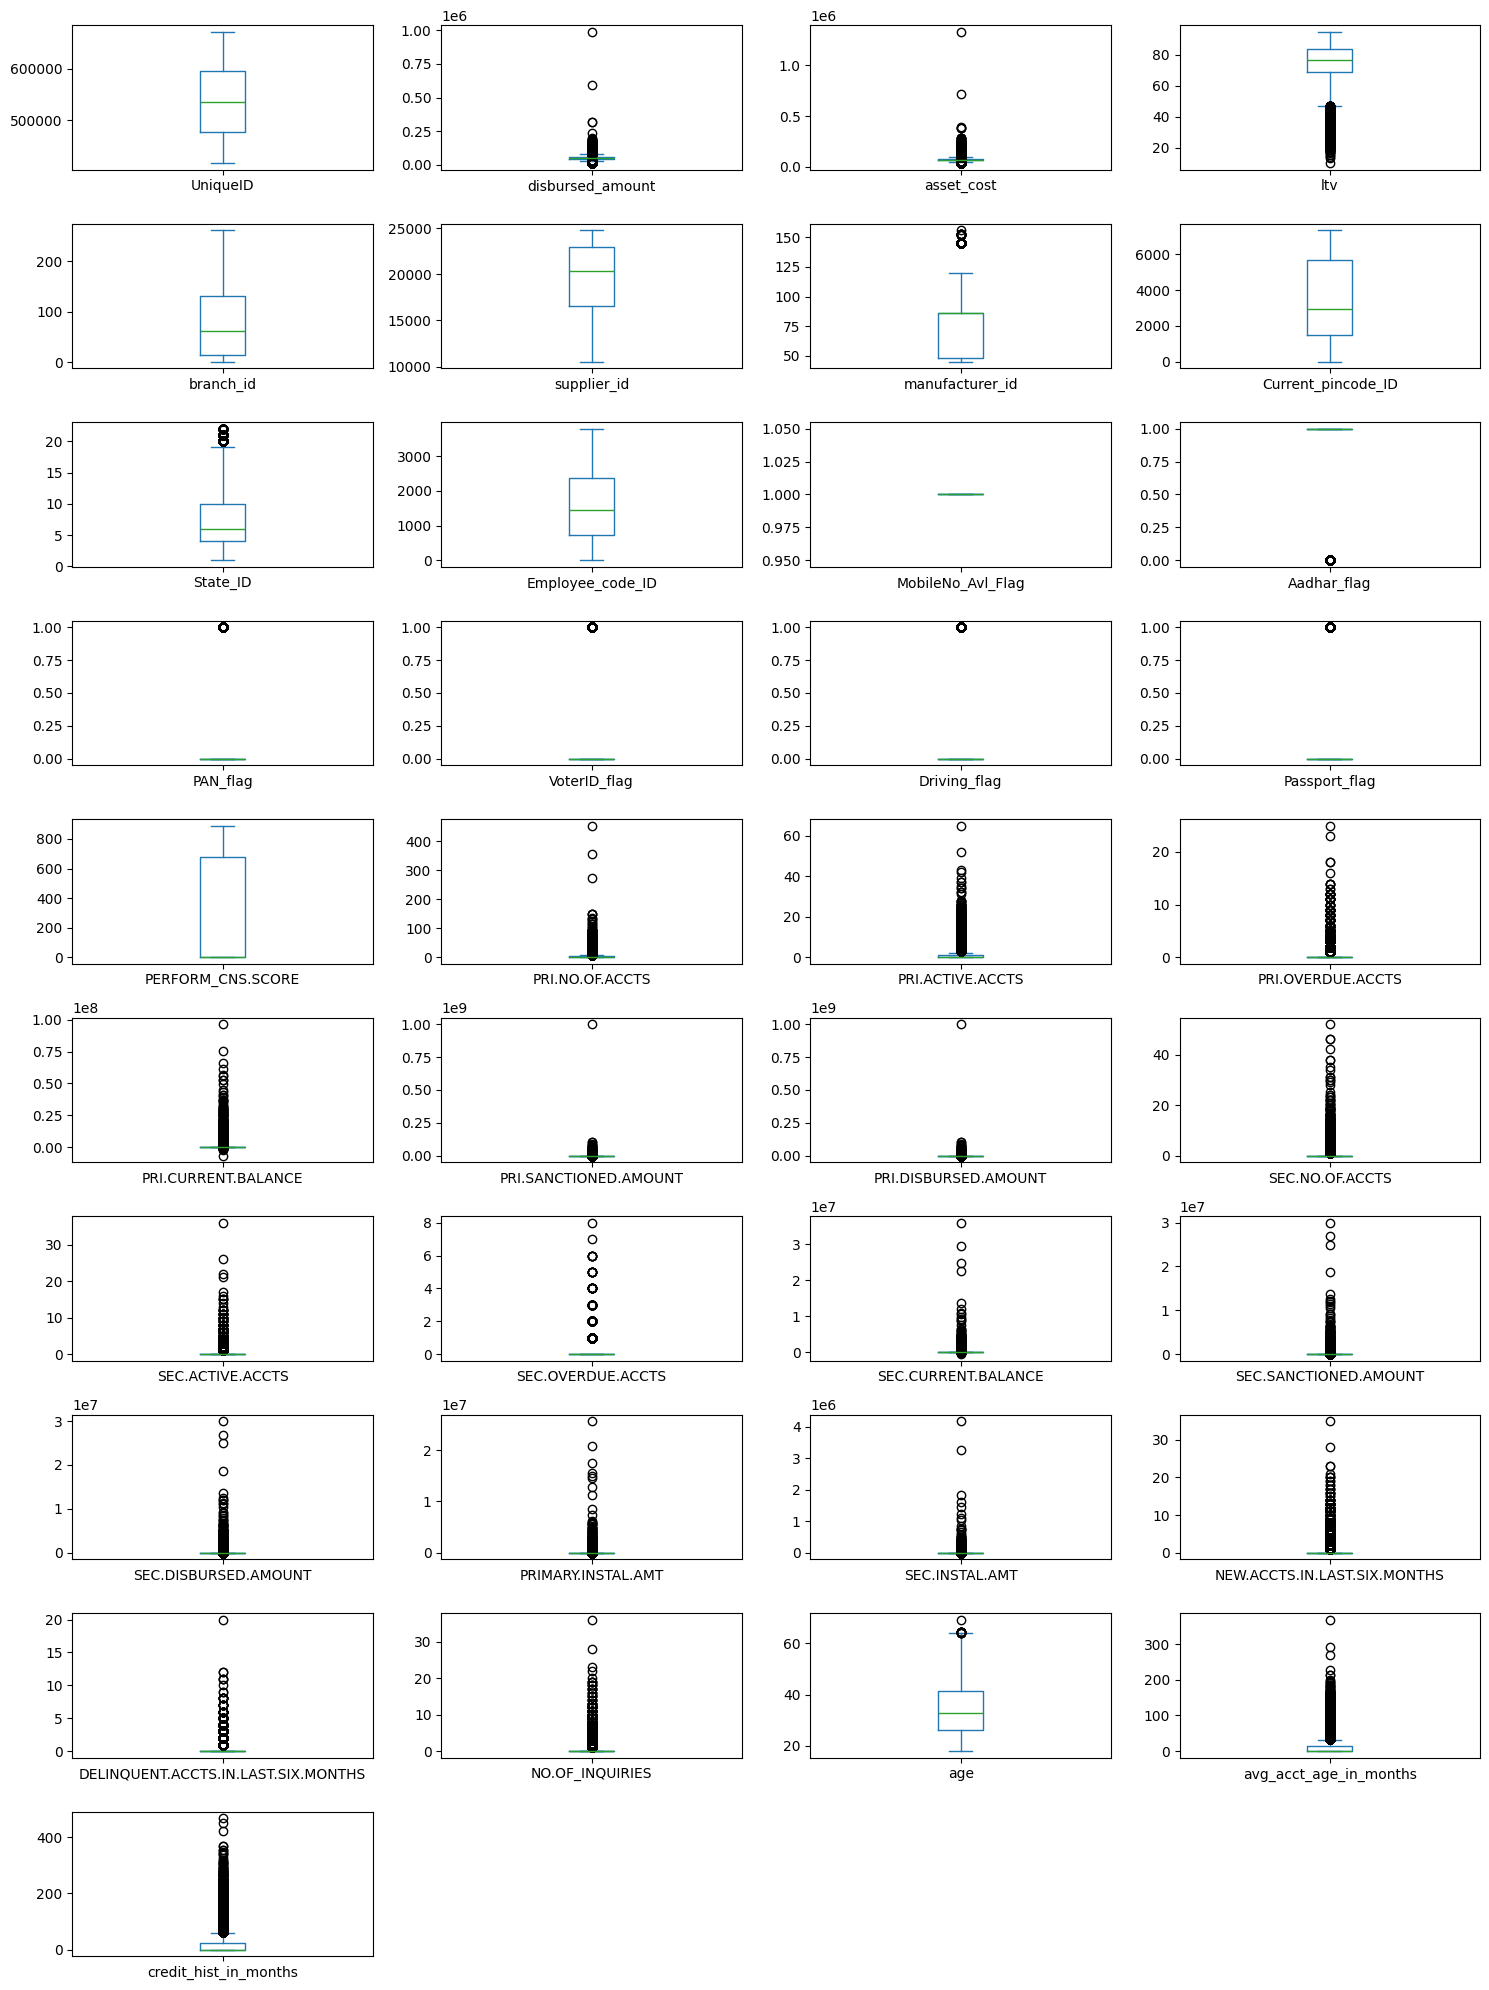

In [33]:
x_train.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

In [34]:
idx = x_train["PRI.SANCTIONED.AMOUNT"].idxmax()
x_train.loc[idx].T

UniqueID                                        598208
disbursed_amount                                 47773
asset_cost                                       85964
ltv                                              59.33
branch_id                                           20
supplier_id                                      16700
manufacturer_id                                     86
Current_pincode_ID                                6434
Employment.Type                          Self employed
State_ID                                             5
Employee_code_ID                                   152
MobileNo_Avl_Flag                                    1
Aadhar_flag                                          1
PAN_flag                                             0
VoterID_flag                                         0
Driving_flag                                         0
Passport_flag                                        0
PERFORM_CNS.SCORE                                  748
PERFORM_CN

In [35]:
x_train = x_train.drop(index=71593)
y_train=y_train.drop(index=71593)

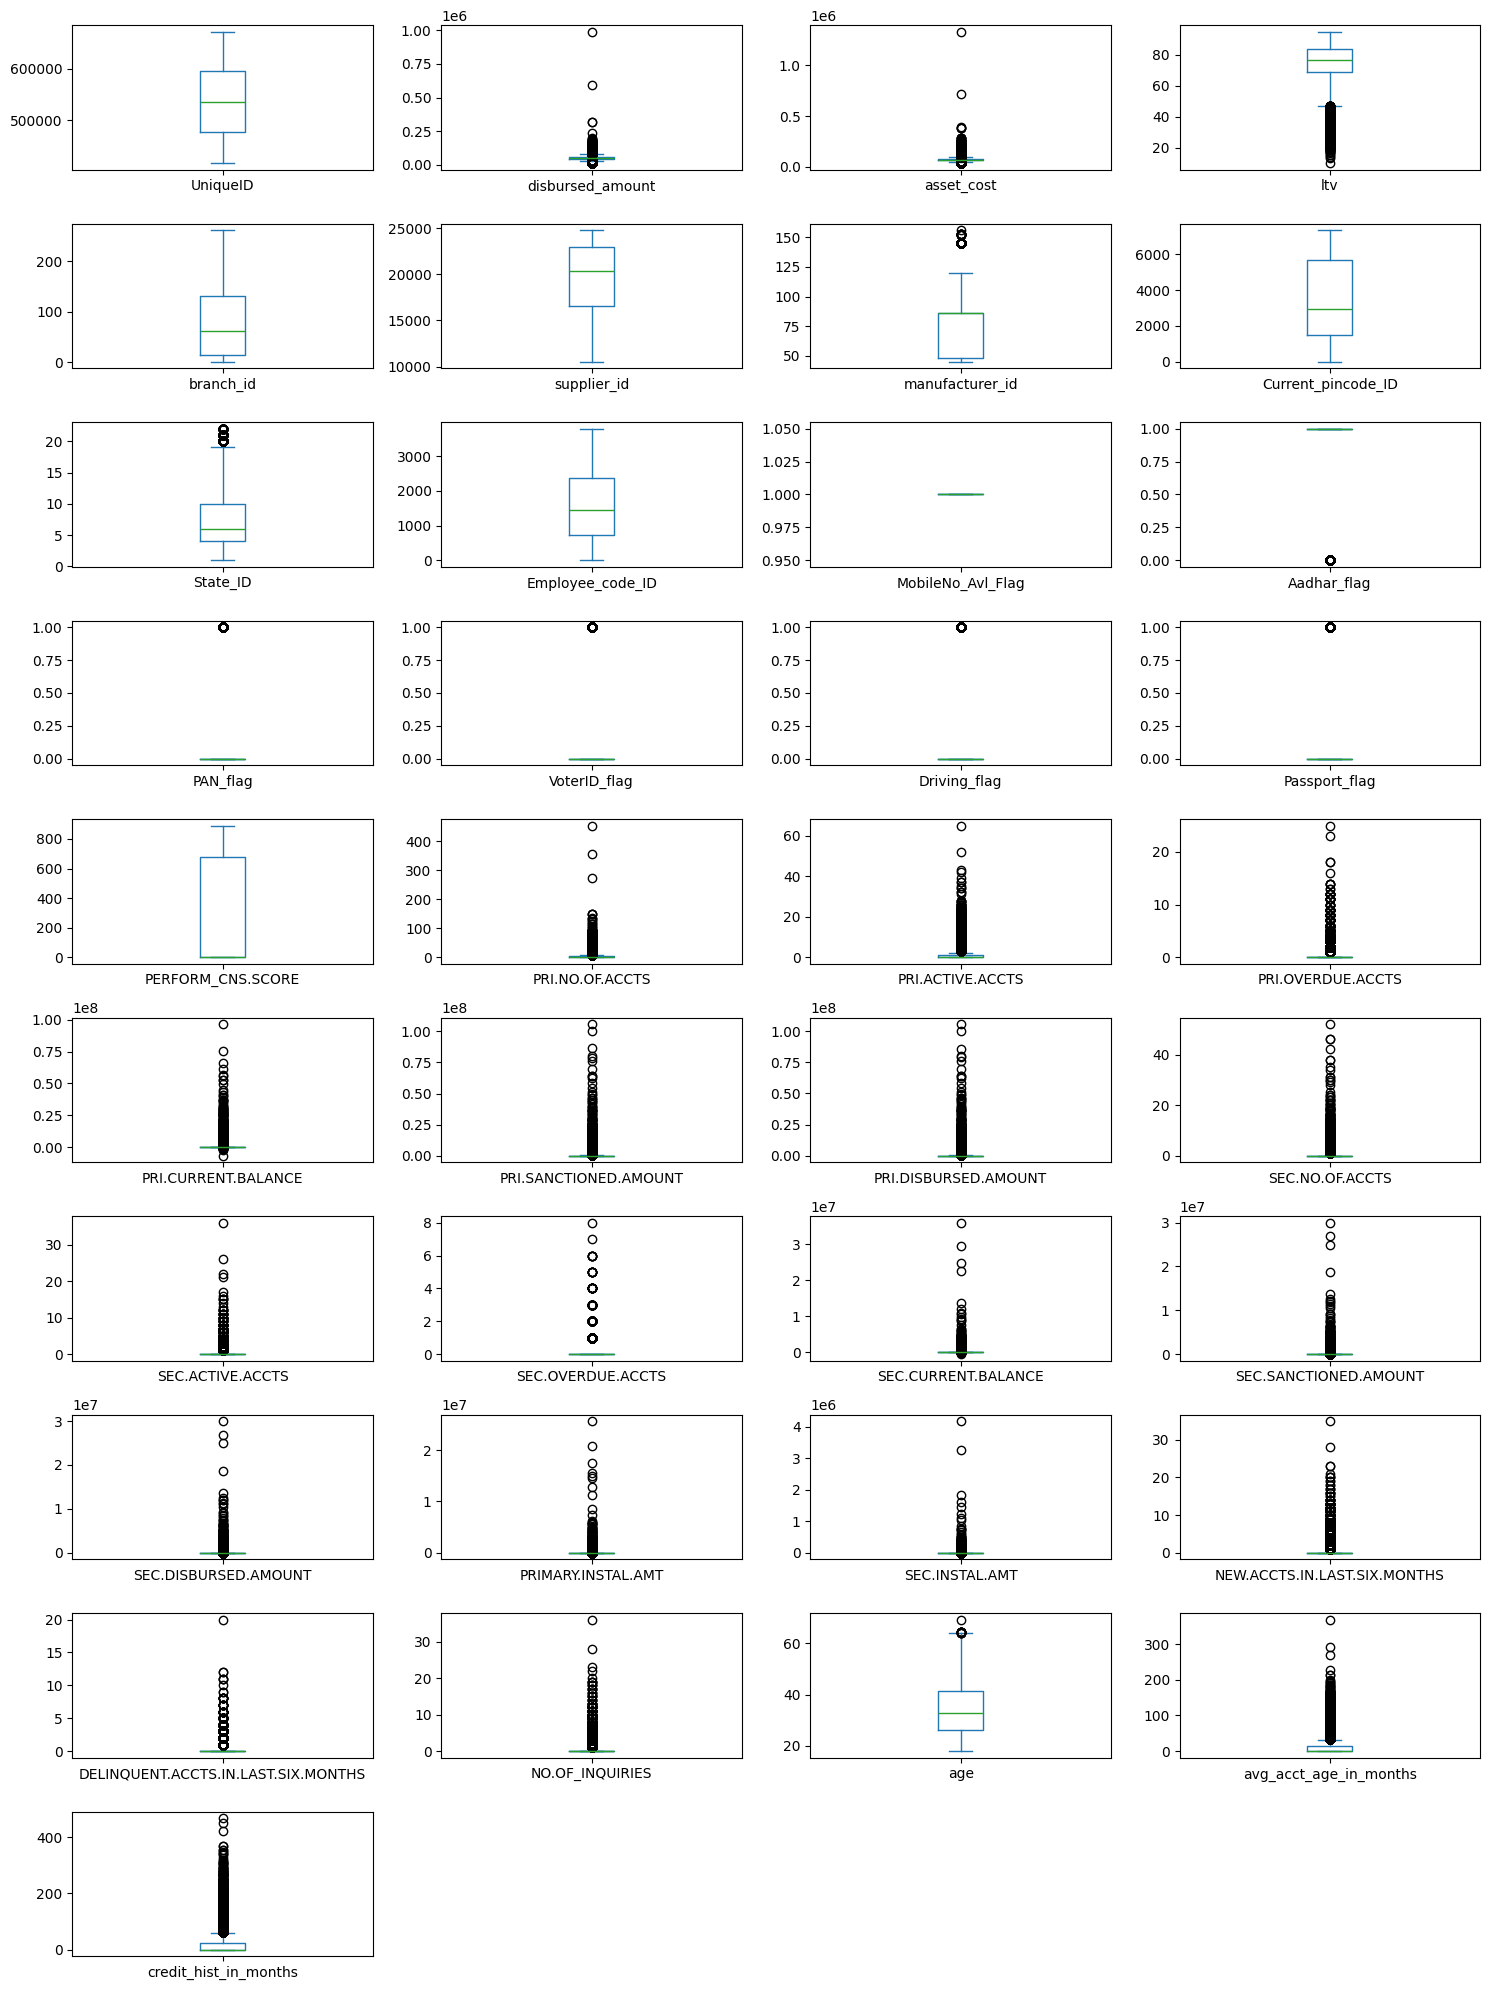

In [36]:
x_train.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

## x_train version for logistic regression

### Outlier && Collinearity Management

In [37]:
x_train_log=x_train.copy()
x_test_log=x_test.copy()

In [38]:
cols = ["disbursed_amount", "asset_cost"]
limits = x_train_log[cols].quantile(0.999)
print(limits)

disbursed_amount    122676.000
asset_cost          189314.832
Name: 0.999, dtype: float64


In [39]:
print((x_train_log[cols] > limits).sum())
print((x_test_log[cols] > limits).sum())

disbursed_amount    186
asset_cost          187
dtype: int64
disbursed_amount    51
asset_cost          50
dtype: int64


In [40]:
x_train_log[cols] = x_train_log[cols].clip(upper=limits, axis=1)
x_test_log[cols] = x_test_log[cols].clip(upper=limits, axis=1)

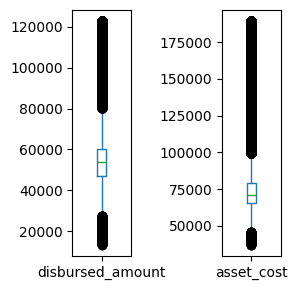

In [41]:
x_train_log[["disbursed_amount", "asset_cost"]].plot(kind='box', subplots=True, layout=(-1, 4), figsize=(6, 3))
plt.tight_layout()
plt.show()

In [42]:
cols = ["disbursed_amount", "asset_cost"]
x_train_log[cols]=np.log1p(x_train_log[cols])

In [43]:
cols = ["disbursed_amount", "asset_cost"]
x_test_log[cols]=np.log1p(x_test_log[cols])

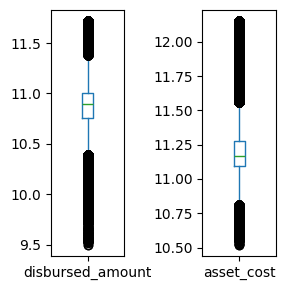

In [44]:
x_train_log[["disbursed_amount", "asset_cost"]].plot(kind='box', subplots=True, layout=(-1, 4), figsize=(6, 3))
plt.tight_layout()
plt.show()

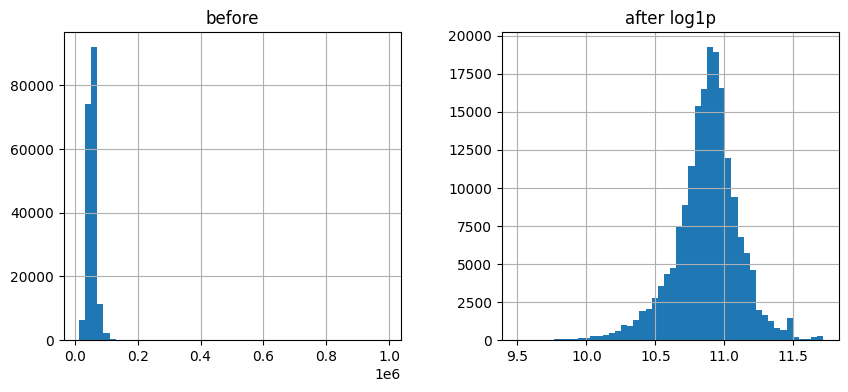

In [45]:
cols = ["disbursed_amount"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0])
ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1])
ax[1].set_title("after log1p")
plt.show()

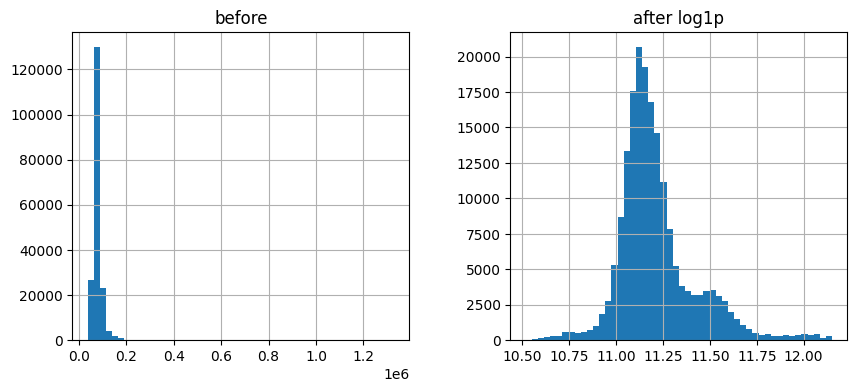

In [46]:
cols = ["asset_cost"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0])
ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1])
ax[1].set_title("after log1p")
plt.show()

In [47]:
train_demo=x_train_log.copy()
train_demo['target']=y_train.copy()

In [48]:
corr = train_demo.corr(numeric_only=True)

In [49]:
print(corr['target'].abs().sort_values(ascending=False))

target                                 1.000000
ltv                                    0.098716
disbursed_amount                       0.087549
PERFORM_CNS.SCORE                      0.058160
State_ID                               0.047385
NO.OF_INQUIRIES                        0.044044
credit_hist_in_months                  0.043767
VoterID_flag                           0.042616
PRI.ACTIVE.ACCTS                       0.042138
PRI.OVERDUE.ACCTS                      0.041772
Aadhar_flag                            0.040607
age                                    0.037630
PRI.NO.OF.ACCTS                        0.036197
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS    0.035106
UniqueID                               0.033487
PRI.SANCTIONED.AMOUNT                  0.031015
branch_id                              0.030759
PRI.DISBURSED.AMOUNT                   0.030578
NEW.ACCTS.IN.LAST.SIX.MONTHS           0.028615
supplier_id                            0.027937
PRI.CURRENT.BALANCE                    0

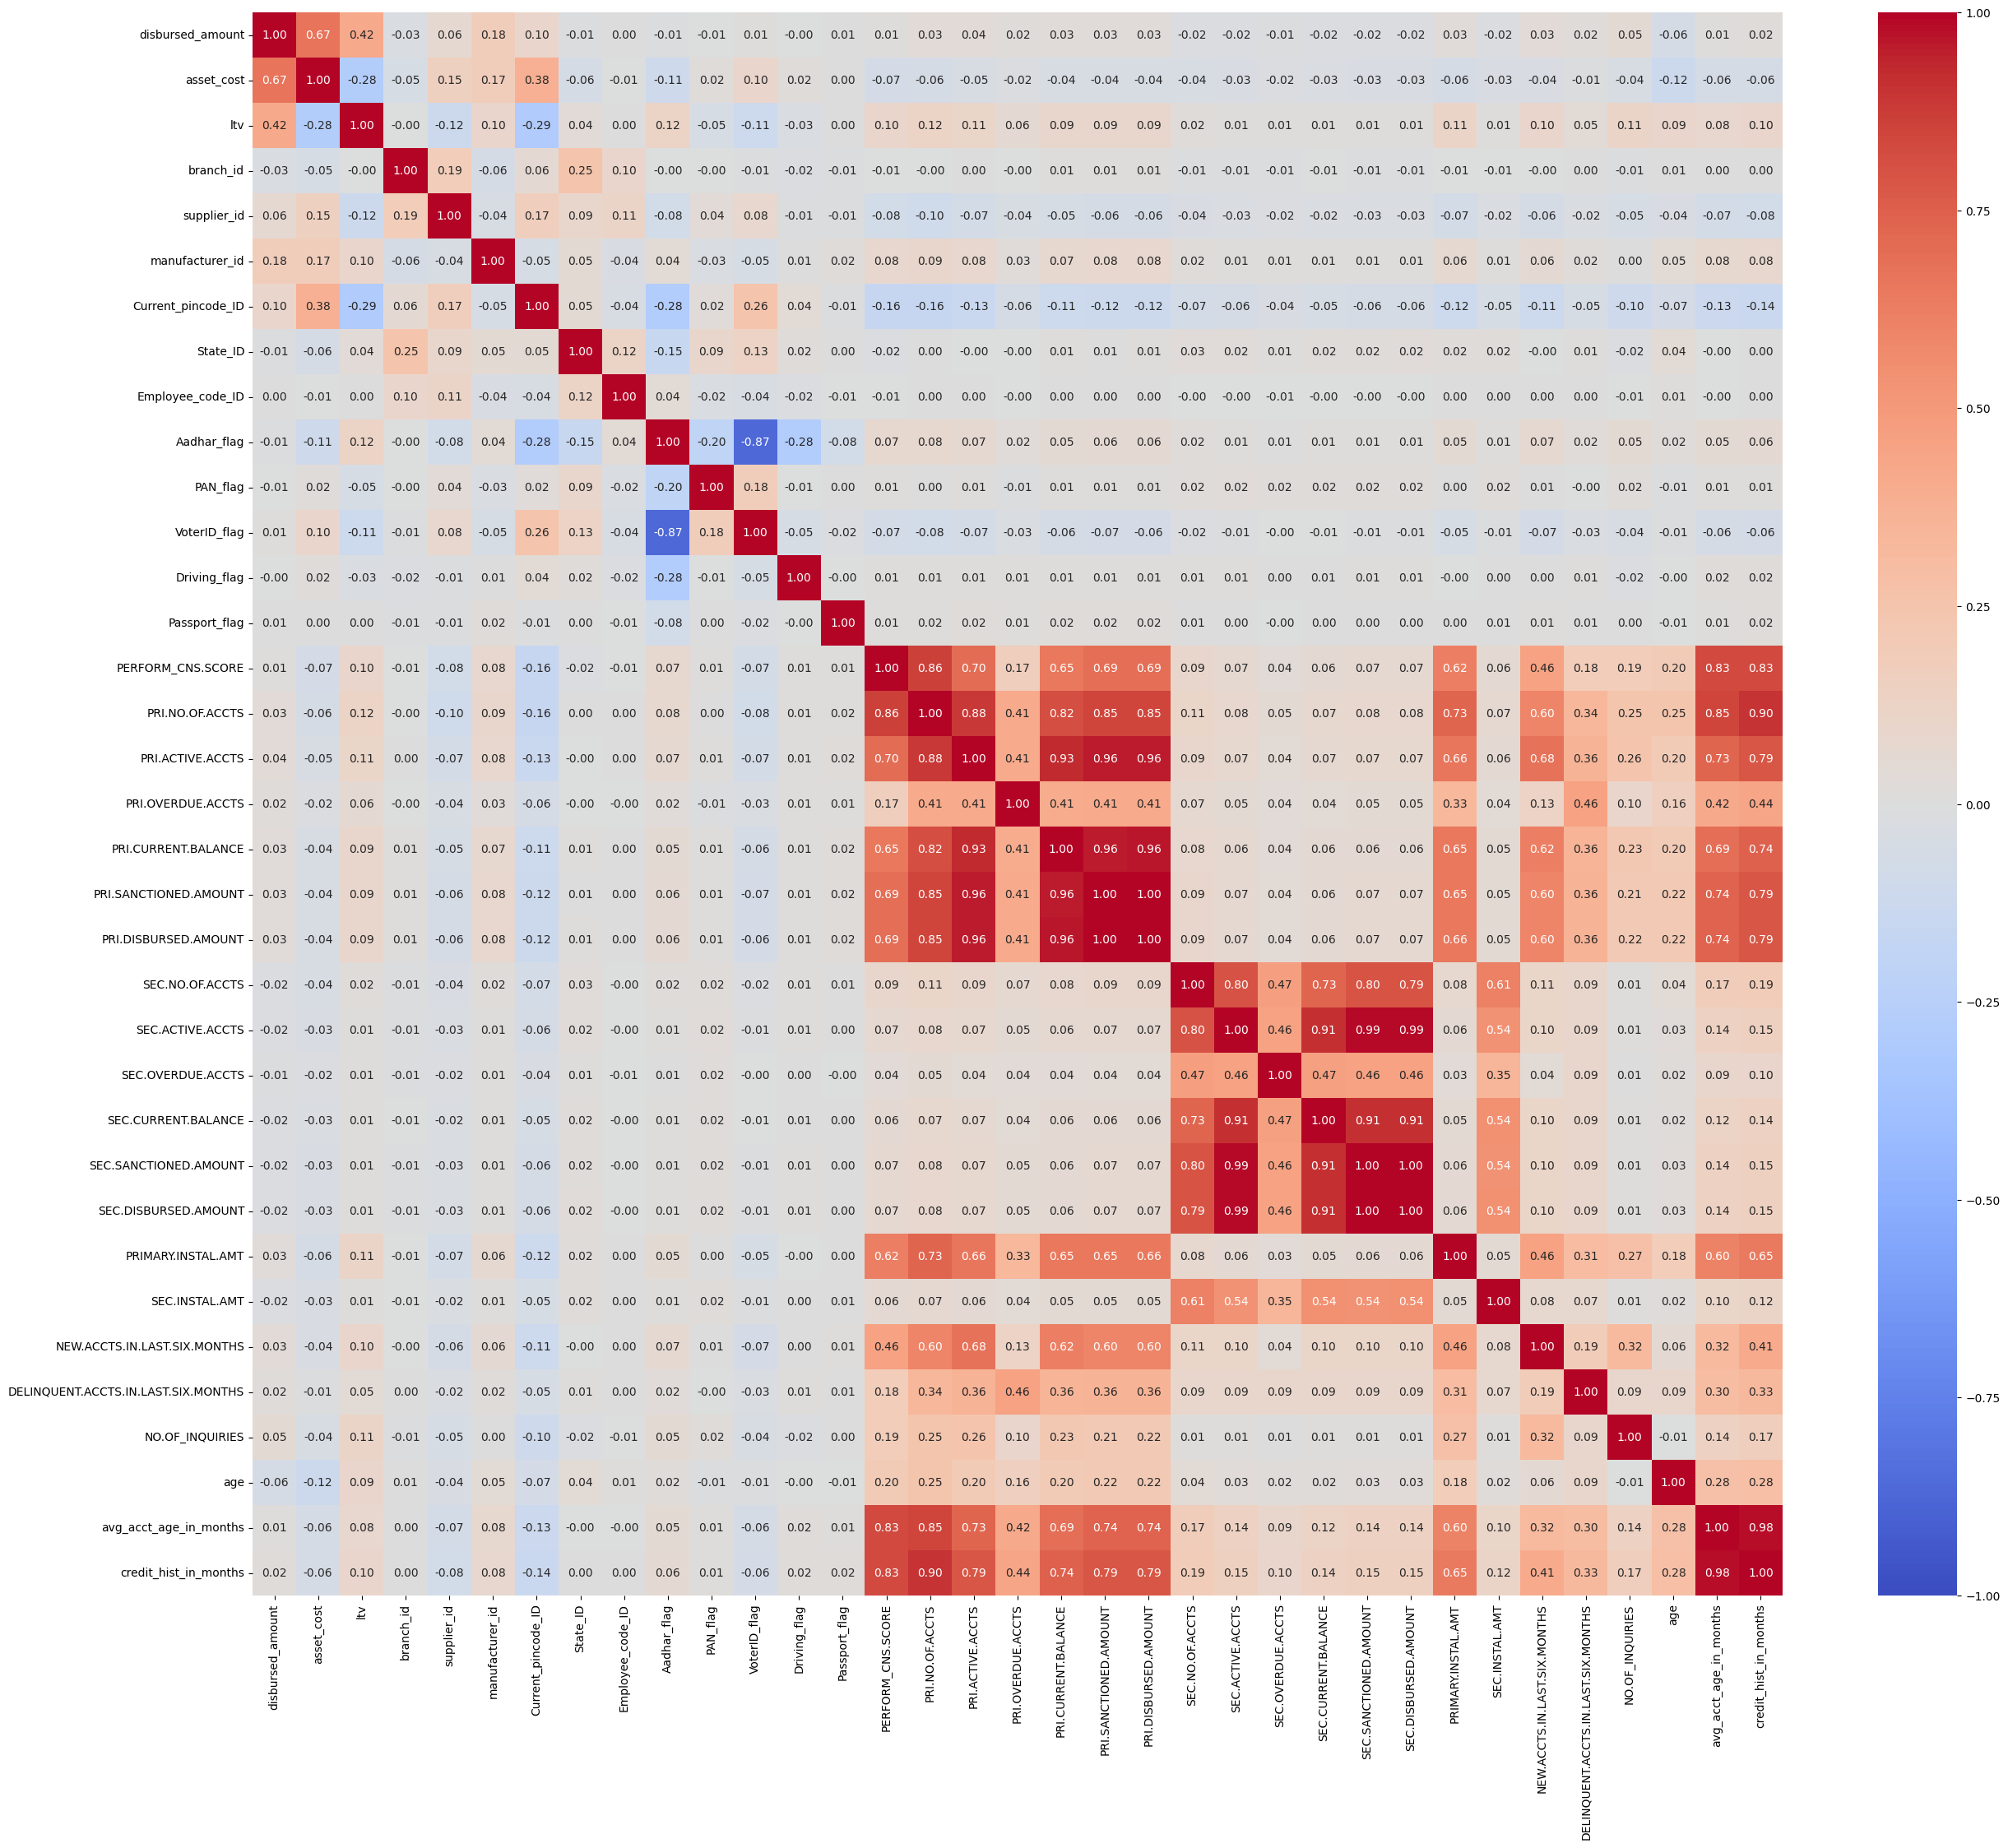

PRI.SANCTIONED.AMOUNT   PRI.DISBURSED.AMOUNT      0.996349
SEC.SANCTIONED.AMOUNT   SEC.DISBURSED.AMOUNT      0.996045
SEC.ACTIVE.ACCTS        SEC.SANCTIONED.AMOUNT     0.989482
                        SEC.DISBURSED.AMOUNT      0.985898
avg_acct_age_in_months  credit_hist_in_months     0.981680
PRI.CURRENT.BALANCE     PRI.DISBURSED.AMOUNT      0.962955
                        PRI.SANCTIONED.AMOUNT     0.958856
PRI.ACTIVE.ACCTS        PRI.SANCTIONED.AMOUNT     0.957991
                        PRI.DISBURSED.AMOUNT      0.957352
                        PRI.CURRENT.BALANCE       0.926072
SEC.CURRENT.BALANCE     SEC.DISBURSED.AMOUNT      0.911512
                        SEC.SANCTIONED.AMOUNT     0.908524
SEC.ACTIVE.ACCTS        SEC.CURRENT.BALANCE       0.907528
PRI.NO.OF.ACCTS         credit_hist_in_months     0.902730
                        PRI.ACTIVE.ACCTS          0.883188
PERFORM_CNS.SCORE       PRI.NO.OF.ACCTS           0.859633
PRI.NO.OF.ACCTS         avg_acct_age_in_months    0.8504

In [50]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Numeric columns only (leave out IDs and the constant flag)
num = x_train_log.select_dtypes("number").drop(columns=["UniqueID", "MobileNo_Avl_Flag"])

# 2. Spearman correlation between the features
corr = num.corr(method="spearman")

# 3. Heatmap
plt.figure(figsize=(30, 25))
sns.heatmap(corr,annot=True, cmap="coolwarm",fmt=".2f", center=0, vmin=-1, vmax=1)
plt.show()

# 4. List the strongest pairs, so you don't have to read the heatmap
pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs[pairs.abs() > 0.8].sort_values(ascending=False))

In [51]:
x_train_log=x_train_log.drop(columns=['PRI.SANCTIONED.AMOUNT','SEC.SANCTIONED.AMOUNT','avg_acct_age_in_months'])

In [52]:
x_test_log=x_test_log.drop(columns=['PRI.SANCTIONED.AMOUNT','SEC.SANCTIONED.AMOUNT','avg_acct_age_in_months'])

In [53]:
sec_cols = ["SEC.NO.OF.ACCTS", "SEC.ACTIVE.ACCTS", "SEC.OVERDUE.ACCTS", "SEC.CURRENT.BALANCE", "SEC.DISBURSED.AMOUNT", "SEC.INSTAL.AMT"]

# 1. Create the flag in both sets (1 = has a secondary account, 0 = none)
x_train_log["has_secondary_account"] = (x_train_log["SEC.NO.OF.ACCTS"] > 0).astype(int)
x_test_log["has_secondary_account"] = (x_test_log["SEC.NO.OF.ACCTS"] > 0).astype(int)

# 2. Check the counts before dropping anything
print(x_train_log["has_secondary_account"].value_counts())
print(x_test_log["has_secondary_account"].value_counts())

# 3. Drop the original SEC columns from both sets
x_train_log = x_train_log.drop(columns=sec_cols)
x_test_log = x_test_log.drop(columns=sec_cols)

has_secondary_account
0    181909
1      4613
Name: count, dtype: int64
has_secondary_account
0    45379
1     1252
Name: count, dtype: int64


In [54]:
x_train_log=x_train_log.drop(columns=['PAN_flag','MobileNo_Avl_Flag','Passport_flag','Driving_flag'])

In [55]:
x_test_log=x_test_log.drop(columns=['PAN_flag','MobileNo_Avl_Flag','Passport_flag','Driving_flag'])

In [56]:
x_train_log.info()

<class 'pandas.core.frame.DataFrame'>
Index: 186522 entries, 192380 to 214103
Data columns (total 27 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   UniqueID                             186522 non-null  int64  
 1   disbursed_amount                     186522 non-null  float64
 2   asset_cost                           186522 non-null  float64
 3   ltv                                  186522 non-null  float64
 4   branch_id                            186522 non-null  int64  
 5   supplier_id                          186522 non-null  int64  
 6   manufacturer_id                      186522 non-null  int64  
 7   Current_pincode_ID                   186522 non-null  int64  
 8   Employment.Type                      186522 non-null  object 
 9   State_ID                             186522 non-null  int64  
 10  Employee_code_ID                     186522 non-null  int64  
 11  Aadhar_flag  

In [57]:
x_test_log.info()

<class 'pandas.core.frame.DataFrame'>
Index: 46631 entries, 52599 to 54239
Data columns (total 27 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   UniqueID                             46631 non-null  int64  
 1   disbursed_amount                     46631 non-null  float64
 2   asset_cost                           46631 non-null  float64
 3   ltv                                  46631 non-null  float64
 4   branch_id                            46631 non-null  int64  
 5   supplier_id                          46631 non-null  int64  
 6   manufacturer_id                      46631 non-null  int64  
 7   Current_pincode_ID                   46631 non-null  int64  
 8   Employment.Type                      46631 non-null  object 
 9   State_ID                             46631 non-null  int64  
 10  Employee_code_ID                     46631 non-null  int64  
 11  Aadhar_flag                  

In [58]:
print(len(x_train_log['UniqueID'].unique()))
print(len(x_train_log['branch_id'].unique()))
print(len(x_train_log['supplier_id'].unique()))
print(len(x_train_log['manufacturer_id'].unique()))
print(len(x_train_log['Current_pincode_ID'].unique()))
print(len(x_train_log['State_ID'].unique()))
print(len(x_train_log['Employee_code_ID'].unique()))

186522
82
2921
11
6512
22
3260


In [59]:
x_train_log=x_train_log.drop(columns=['UniqueID','branch_id','supplier_id','Employee_code_ID','Current_pincode_ID'])
x_test_log=x_test_log.drop(columns=['UniqueID','branch_id','supplier_id','Employee_code_ID','Current_pincode_ID'])

In [60]:
x_train_log.info()

<class 'pandas.core.frame.DataFrame'>
Index: 186522 entries, 192380 to 214103
Data columns (total 22 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   disbursed_amount                     186522 non-null  float64
 1   asset_cost                           186522 non-null  float64
 2   ltv                                  186522 non-null  float64
 3   manufacturer_id                      186522 non-null  int64  
 4   Employment.Type                      186522 non-null  object 
 5   State_ID                             186522 non-null  int64  
 6   Aadhar_flag                          186522 non-null  int64  
 7   VoterID_flag                         186522 non-null  int64  
 8   PERFORM_CNS.SCORE                    186522 non-null  int64  
 9   PERFORM_CNS.SCORE.DESCRIPTION        186522 non-null  object 
 10  PRI.NO.OF.ACCTS                      186522 non-null  int64  
 11  PRI.ACTIVE.AC

In [61]:
x_train_log.head()

,disbursed_amount,asset_cost,ltv,manufacturer_id,Employment.Type,State_ID,Aadhar_flag,VoterID_flag,PERFORM_CNS.SCORE,PERFORM_CNS.SCORE.DESCRIPTION,...,PRI.OVERDUE.ACCTS,PRI.CURRENT.BALANCE,PRI.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,age,credit_hist_in_months,has_secondary_account
192380,10.953610,11.123299,88.59,86,Salaried,9,1,0,680,F-Low Risk,...,0,63885,101679,3320,3,0,0,35.624914,11,0
43291,10.750342,11.247748,65.18,45,Self employed,3,1,0,0,No Bureau History Available,...,0,0,0,0,0,0,0,36.657084,0,0
210644,10.324990,11.220472,41.53,86,Self employed,17,1,0,0,No Bureau History Available,...,0,0,0,0,0,0,0,34.724162,0,0
50259,11.042089,11.430967,70.01,48,Self employed,3,1,0,749,C-Very Low Risk,...,0,40404,61100,6736,1,0,0,25.420945,22,0
158140,10.906250,11.074436,87.60,45,Self employed,4,1,0,300,M-Very High Risk,...,1,0,0,0,0,0,2,48.134155,0,0


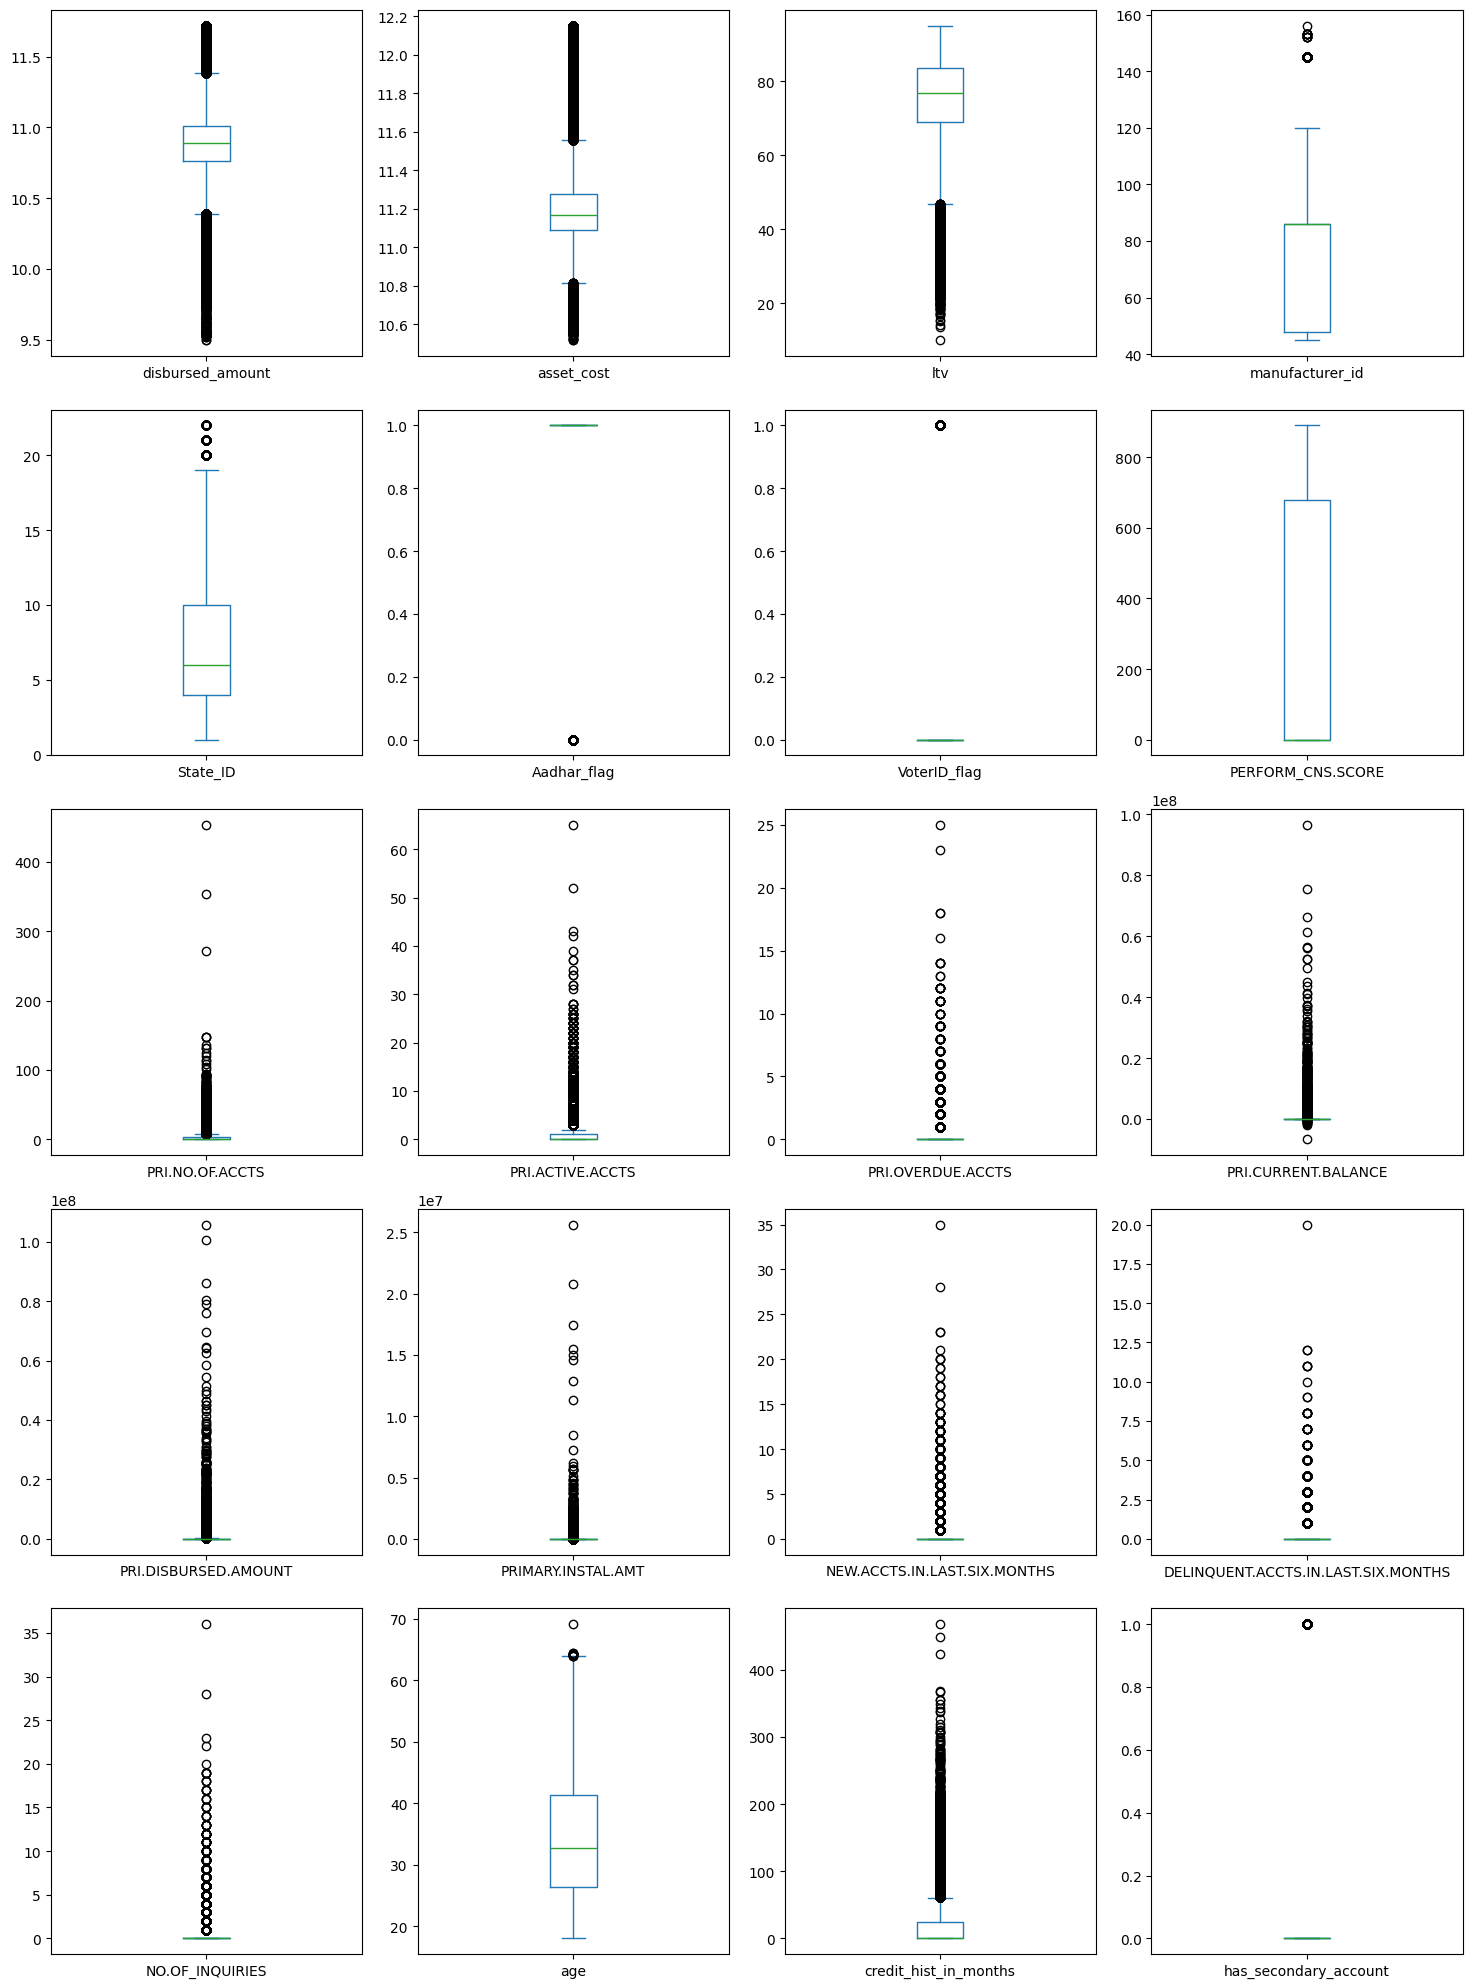

In [62]:
x_train_log.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

In [63]:
x_train_log['PERFORM_CNS.SCORE'].unique()

array([680,   0, 749, 300, 738, 626, 585, 634, 692, 732, 723, 597, 446,
       825, 613, 691, 836, 761,  18,  15, 763, 736, 832, 570, 760, 708,
       792, 756, 684, 706, 719, 631, 583, 783, 824, 490, 690, 365, 369,
       592, 466, 608, 456, 331, 431, 401, 366, 374, 766, 753, 830, 674,
       737, 327, 596, 566, 567, 609, 710,  17, 455, 740, 521,  14, 754,
       721, 451, 435, 743, 709, 774, 488, 615, 659,  16, 665, 810, 679,
       429, 580, 614, 437, 726, 739, 771, 657, 569, 762, 412, 542, 544,
       696, 508, 705, 727, 622, 572, 582, 403, 606, 460, 650, 590, 540,
       667, 714, 675, 368, 780, 571, 605, 687, 458, 681, 637, 656, 525,
       627, 621, 617, 510, 728, 818, 425, 442, 603, 678, 769, 653, 782,
       699, 563, 502, 588, 716, 845, 623, 796, 816, 635, 652, 643, 530,
       662, 758, 501, 390, 811, 574, 707, 561, 669, 364, 638, 423, 646,
       648, 447, 385, 576, 755, 640, 785, 601, 789, 419, 459, 676, 408,
       598, 568, 538, 586, 595, 788, 786, 697, 602, 651, 703, 62

In [64]:
x_train_log['PERFORM_CNS.SCORE.DESCRIPTION'].unique()

array(['F-Low Risk', 'No Bureau History Available', 'C-Very Low Risk',
       'M-Very High Risk', 'H-Medium Risk', 'I-Medium Risk', 'G-Low Risk',
       'E-Low Risk', 'D-Very Low Risk', 'K-High Risk', 'A-Very Low Risk',
       'B-Very Low Risk',
       'Not Scored: No Updates available in last 36 months',
       'Not Scored: Sufficient History Not Available', 'J-High Risk',
       'L-Very High Risk',
       'Not Scored: Not Enough Info available on the customer',
       'Not Scored: Only a Guarantor',
       'Not Scored: No Activity seen on the customer (Inactive)',
       'Not Scored: More than 50 active Accounts found'], dtype=object)

In [65]:
x_train_log['PERFORM_CNS.SCORE.DESCRIPTION'].nunique()

20

In [66]:
x_train_log['PERFORM_CNS.SCORE.DESCRIPTION'].value_counts()

PERFORM_CNS.SCORE.DESCRIPTION
No Bureau History Available                                93498
C-Very Low Risk                                            12822
A-Very Low Risk                                            11314
D-Very Low Risk                                             9094
B-Very Low Risk                                             7376
M-Very High Risk                                            7061
F-Low Risk                                                  6800
K-High Risk                                                 6551
H-Medium Risk                                               5477
E-Low Risk                                                  4697
I-Medium Risk                                               4467
G-Low Risk                                                  3199
Not Scored: Sufficient History Not Available                3029
J-High Risk                                                 2981
Not Scored: Not Enough Info available on the customer       

In [67]:
x_train_log['PERFORM_CNS.SCORE.DESCRIPTION'] = x_train_log['PERFORM_CNS.SCORE.DESCRIPTION'].replace('Not Scored: More than 50 active Accounts found', 'Not Scored: Not Enough Info available on the customer')
x_test_log['PERFORM_CNS.SCORE.DESCRIPTION'] = x_test_log['PERFORM_CNS.SCORE.DESCRIPTION'].replace('Not Scored: More than 50 active Accounts found', 'Not Scored: Not Enough Info available on the customer')

In [68]:
x_train_log=x_train_log.drop(columns=['PERFORM_CNS.SCORE'])
x_test_log=x_test_log.drop(columns=['PERFORM_CNS.SCORE'])

In [69]:
x_train_log.head()

,disbursed_amount,asset_cost,ltv,manufacturer_id,Employment.Type,State_ID,Aadhar_flag,VoterID_flag,PERFORM_CNS.SCORE.DESCRIPTION,PRI.NO.OF.ACCTS,...,PRI.OVERDUE.ACCTS,PRI.CURRENT.BALANCE,PRI.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,age,credit_hist_in_months,has_secondary_account
192380,10.953610,11.123299,88.59,86,Salaried,9,1,0,F-Low Risk,5,...,0,63885,101679,3320,3,0,0,35.624914,11,0
43291,10.750342,11.247748,65.18,45,Self employed,3,1,0,No Bureau History Available,0,...,0,0,0,0,0,0,0,36.657084,0,0
210644,10.324990,11.220472,41.53,86,Self employed,17,1,0,No Bureau History Available,0,...,0,0,0,0,0,0,0,34.724162,0,0
50259,11.042089,11.430967,70.01,48,Self employed,3,1,0,C-Very Low Risk,3,...,0,40404,61100,6736,1,0,0,25.420945,22,0
158140,10.906250,11.074436,87.60,45,Self employed,4,1,0,M-Very High Risk,1,...,1,0,0,0,0,0,2,48.134155,0,0


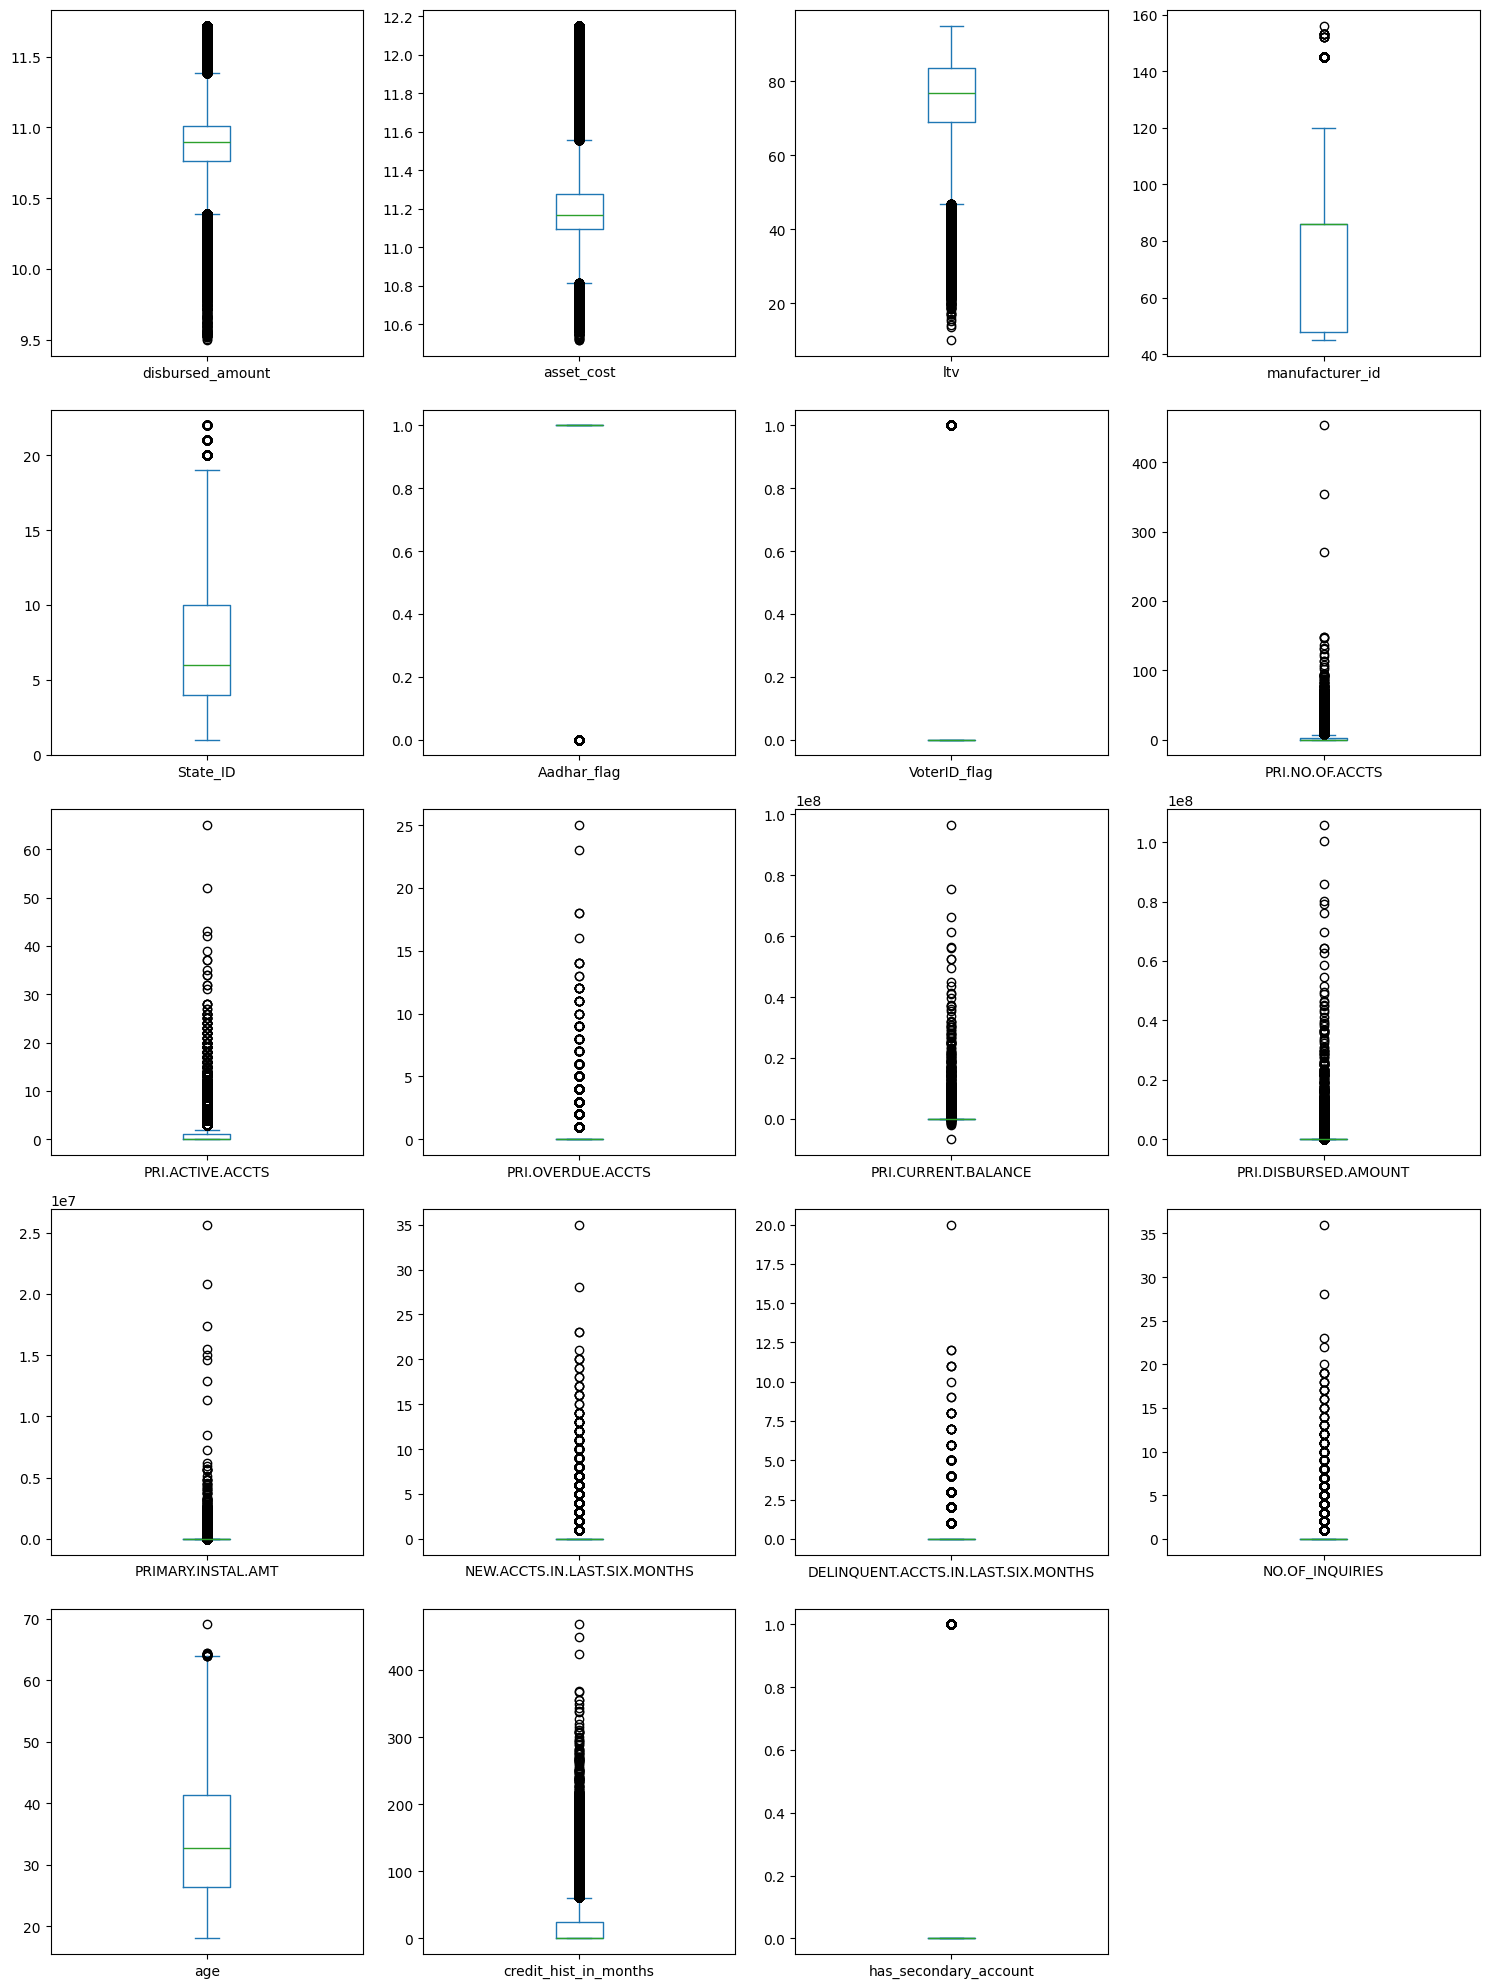

In [70]:
x_train_log.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

In [71]:
x_train_log["PRI.CURRENT.BALANCE"] = x_train_log["PRI.CURRENT.BALANCE"].clip(lower=0)
x_test_log["PRI.CURRENT.BALANCE"] = x_test_log["PRI.CURRENT.BALANCE"].clip(lower=0)

In [72]:
cols = ['PRI.CURRENT.BALANCE','PRI.DISBURSED.AMOUNT','PRIMARY.INSTAL.AMT']
limits = x_train_log[cols].quantile(0.999)
print(limits)

PRI.CURRENT.BALANCE     9.882495e+06
PRI.DISBURSED.AMOUNT    1.217346e+07
PRIMARY.INSTAL.AMT      1.548861e+06
Name: 0.999, dtype: float64


In [73]:
print((x_train_log[cols] > limits).sum())
print((x_test_log[cols] > limits).sum())

PRI.CURRENT.BALANCE     187
PRI.DISBURSED.AMOUNT    187
PRIMARY.INSTAL.AMT      187
dtype: int64
PRI.CURRENT.BALANCE     53
PRI.DISBURSED.AMOUNT    53
PRIMARY.INSTAL.AMT      41
dtype: int64


In [74]:
x_train_log[cols] = x_train_log[cols].clip(upper=limits, axis=1)
x_test_log[cols] = x_test_log[cols].clip(upper=limits, axis=1)

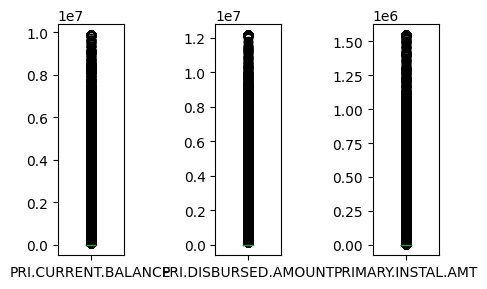

In [75]:
x_train_log[['PRI.CURRENT.BALANCE','PRI.DISBURSED.AMOUNT','PRIMARY.INSTAL.AMT']].plot(kind='box', subplots=True, layout=(-1, 4), figsize=(6, 3))
plt.tight_layout()
plt.show()

In [76]:
cols = ['PRI.CURRENT.BALANCE','PRI.DISBURSED.AMOUNT','PRIMARY.INSTAL.AMT']
x_train_log[cols]=np.log1p(x_train_log[cols])

In [77]:
cols = ['PRI.CURRENT.BALANCE','PRI.DISBURSED.AMOUNT','PRIMARY.INSTAL.AMT']
x_test_log[cols]=np.log1p(x_test_log[cols])

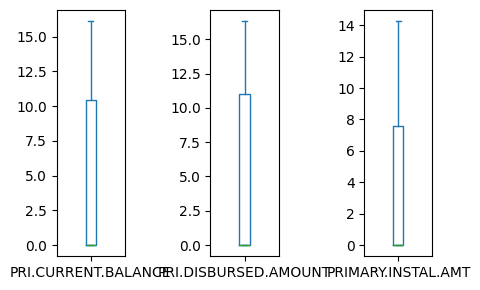

In [78]:
x_train_log[['PRI.CURRENT.BALANCE','PRI.DISBURSED.AMOUNT','PRIMARY.INSTAL.AMT']].plot(kind='box', subplots=True, layout=(-1, 4), figsize=(6, 3))
plt.tight_layout()
plt.show()

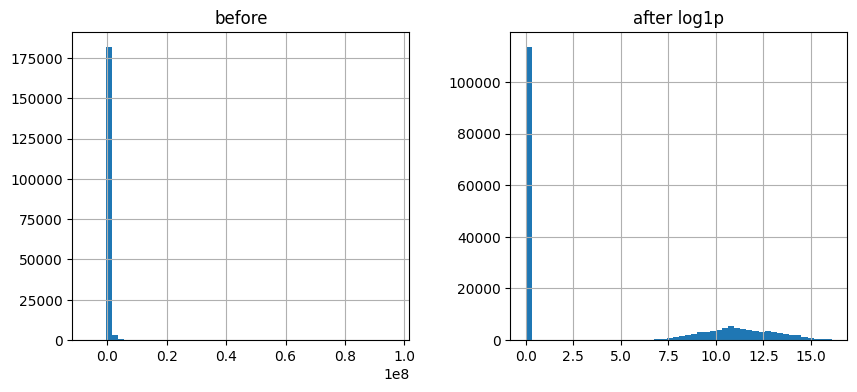

In [79]:
cols = ['PRI.CURRENT.BALANCE']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

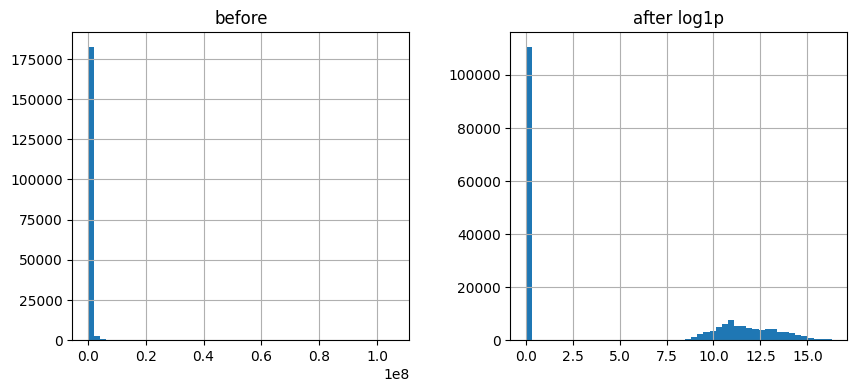

In [80]:
cols = ['PRI.DISBURSED.AMOUNT']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

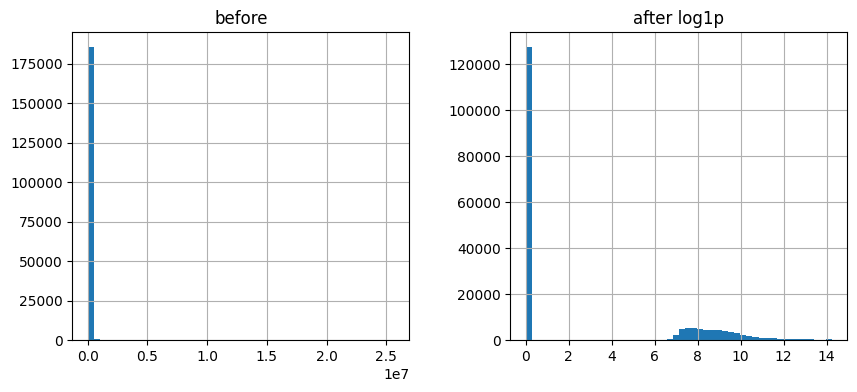

In [81]:
cols = ['PRIMARY.INSTAL.AMT']
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

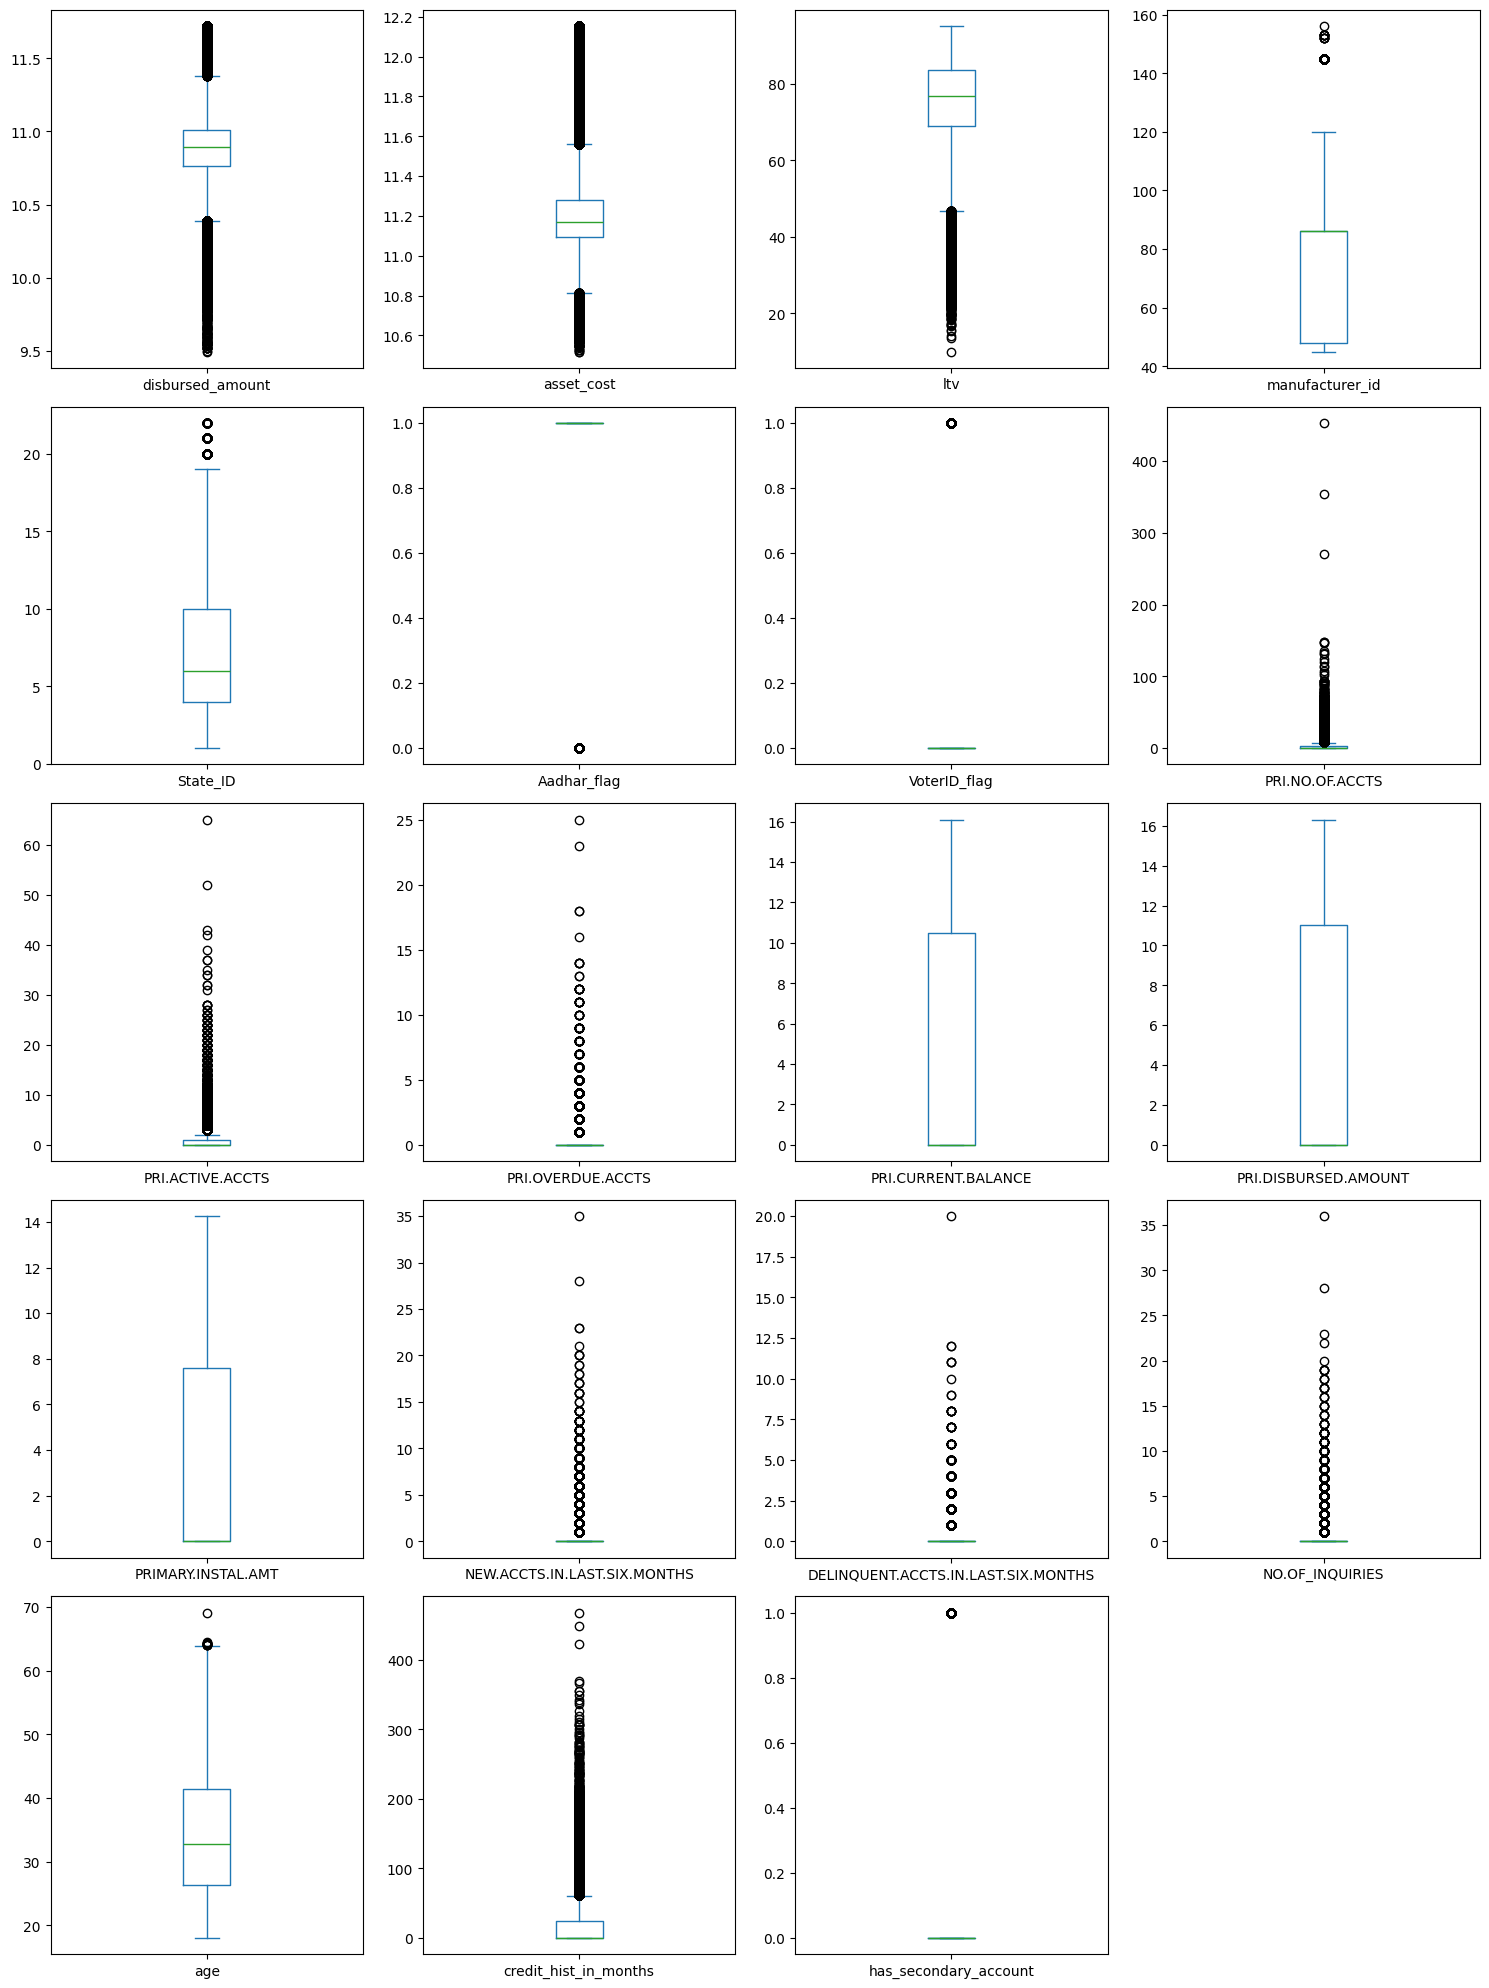

In [82]:
x_train_log.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

In [83]:
cols = ["PRI.NO.OF.ACCTS", "PRI.ACTIVE.ACCTS", "PRI.OVERDUE.ACCTS",
        "NEW.ACCTS.IN.LAST.SIX.MONTHS", "DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS", "NO.OF_INQUIRIES"]

# 1. Limits from the training set only
limits = x_train_log[cols].quantile(0.999)
print(limits)
print((x_train_log[cols] > limits).sum())
print((x_test_log[cols] > limits).sum())

# 2. Cap both sets with the same limits
x_train_log[cols] = x_train_log[cols].clip(upper=limits, axis=1)
x_test_log[cols] = x_test_log[cols].clip(upper=limits, axis=1)

# 3. log1p on both sets (run this once only)
x_train_log[cols] = np.log1p(x_train_log[cols])
x_test_log[cols] = np.log1p(x_test_log[cols])

PRI.NO.OF.ACCTS                        50.0
PRI.ACTIVE.ACCTS                       16.0
PRI.OVERDUE.ACCTS                       5.0
NEW.ACCTS.IN.LAST.SIX.MONTHS            9.0
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS     4.0
NO.OF_INQUIRIES                         8.0
Name: 0.999, dtype: float64
PRI.NO.OF.ACCTS                        177
PRI.ACTIVE.ACCTS                       160
PRI.OVERDUE.ACCTS                      181
NEW.ACCTS.IN.LAST.SIX.MONTHS           125
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS     87
NO.OF_INQUIRIES                        116
dtype: int64
PRI.NO.OF.ACCTS                        42
PRI.ACTIVE.ACCTS                       43
PRI.OVERDUE.ACCTS                      50
NEW.ACCTS.IN.LAST.SIX.MONTHS           34
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS    22
NO.OF_INQUIRIES                        34
dtype: int64


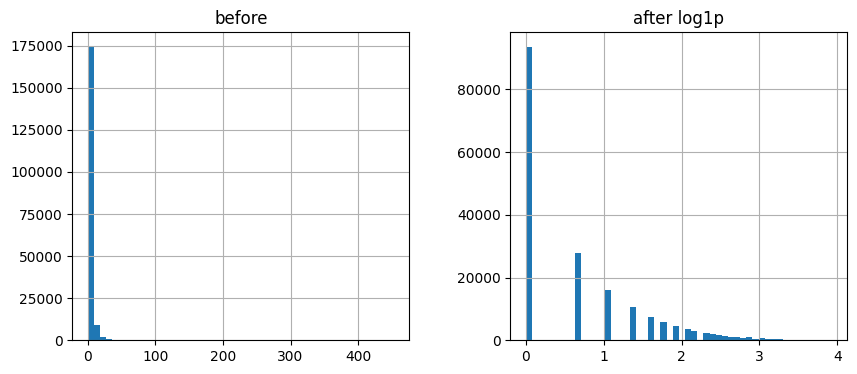

In [84]:
cols = ["PRI.NO.OF.ACCTS"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

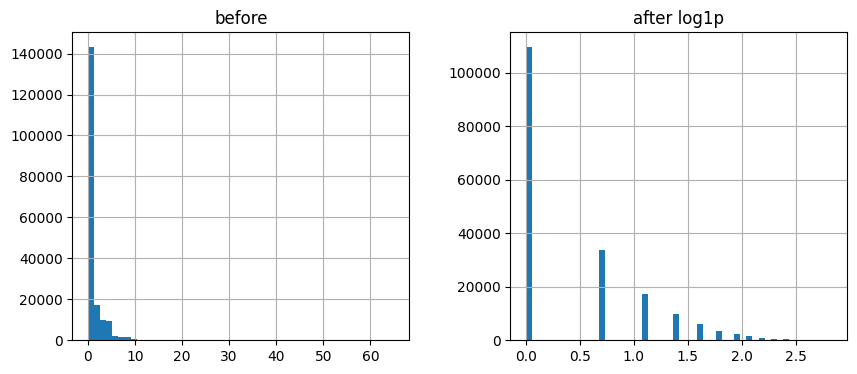

In [85]:
cols = ["PRI.ACTIVE.ACCTS"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

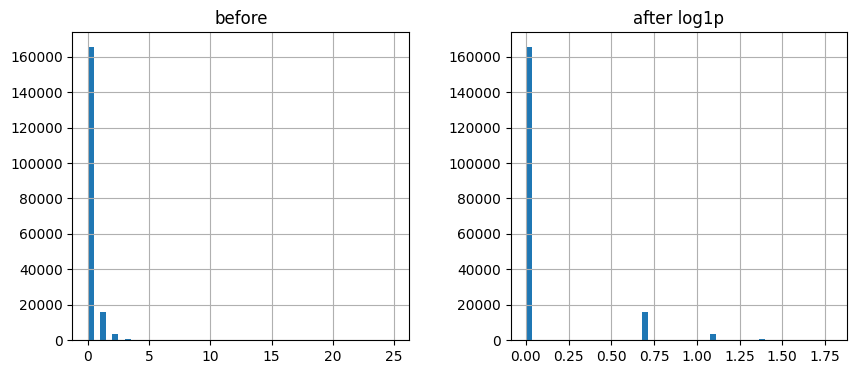

In [86]:
cols = ["PRI.OVERDUE.ACCTS"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

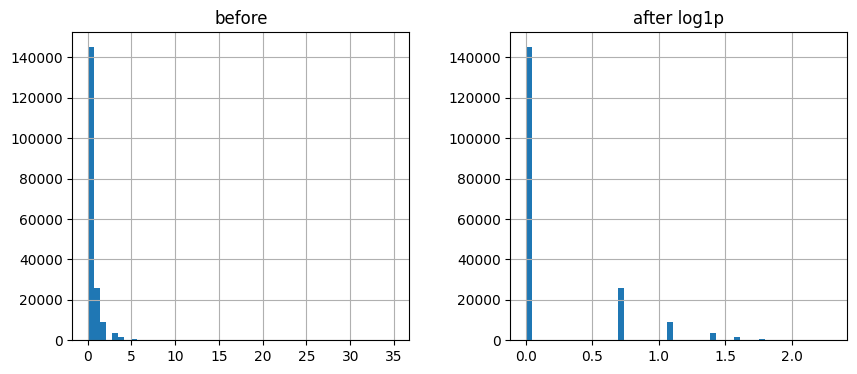

In [87]:
cols = ["NEW.ACCTS.IN.LAST.SIX.MONTHS"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

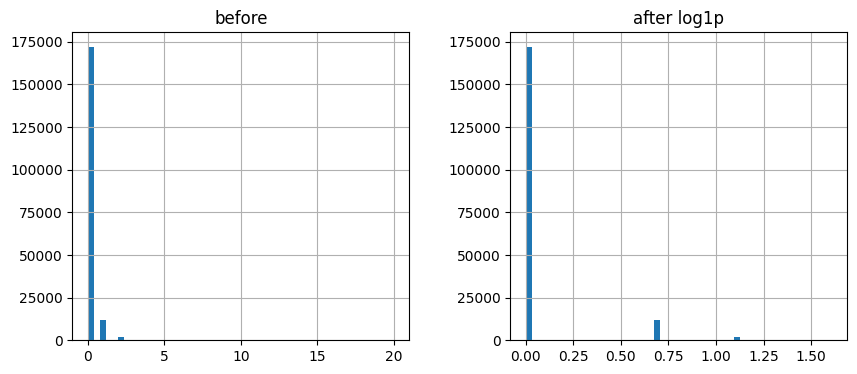

In [88]:
cols = ["DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

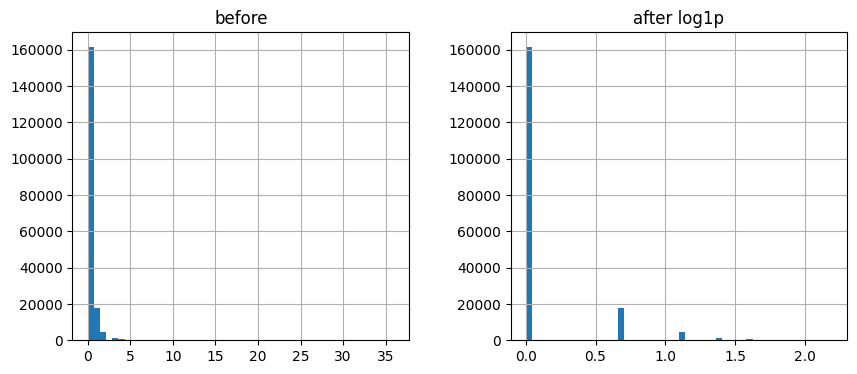

In [89]:
cols = ["NO.OF_INQUIRIES"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

In [90]:
c = "credit_hist_in_months"
limit = x_train_log[c].quantile(0.999)      # learned from train only
print(limit)
print((x_train_log[c] > limit).sum())
print((x_test_log[c] > limit).sum())

x_train_log[c] = np.log1p(x_train_log[c].clip(upper=limit))
x_test_log[c]  = np.log1p(x_test_log[c].clip(upper=limit))

196.0
184
62


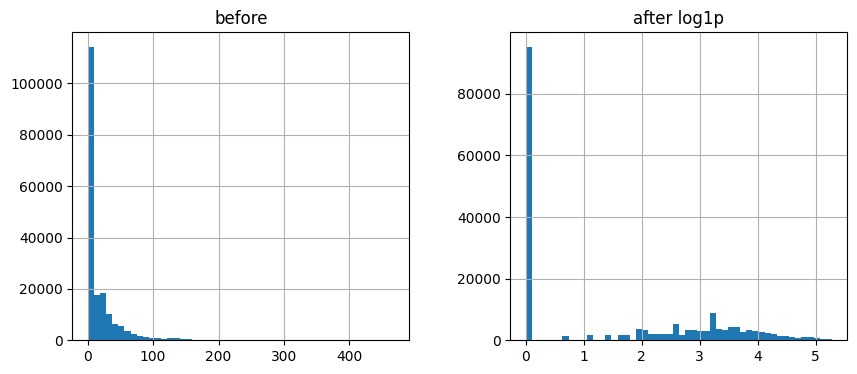

In [91]:
cols = ["credit_hist_in_months"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
x_train[cols].hist(bins=50, ax=ax[0]);           ax[0].set_title("before")
x_train_log[cols].hist(bins=50, ax=ax[1]); ax[1].set_title("after log1p")
plt.show()

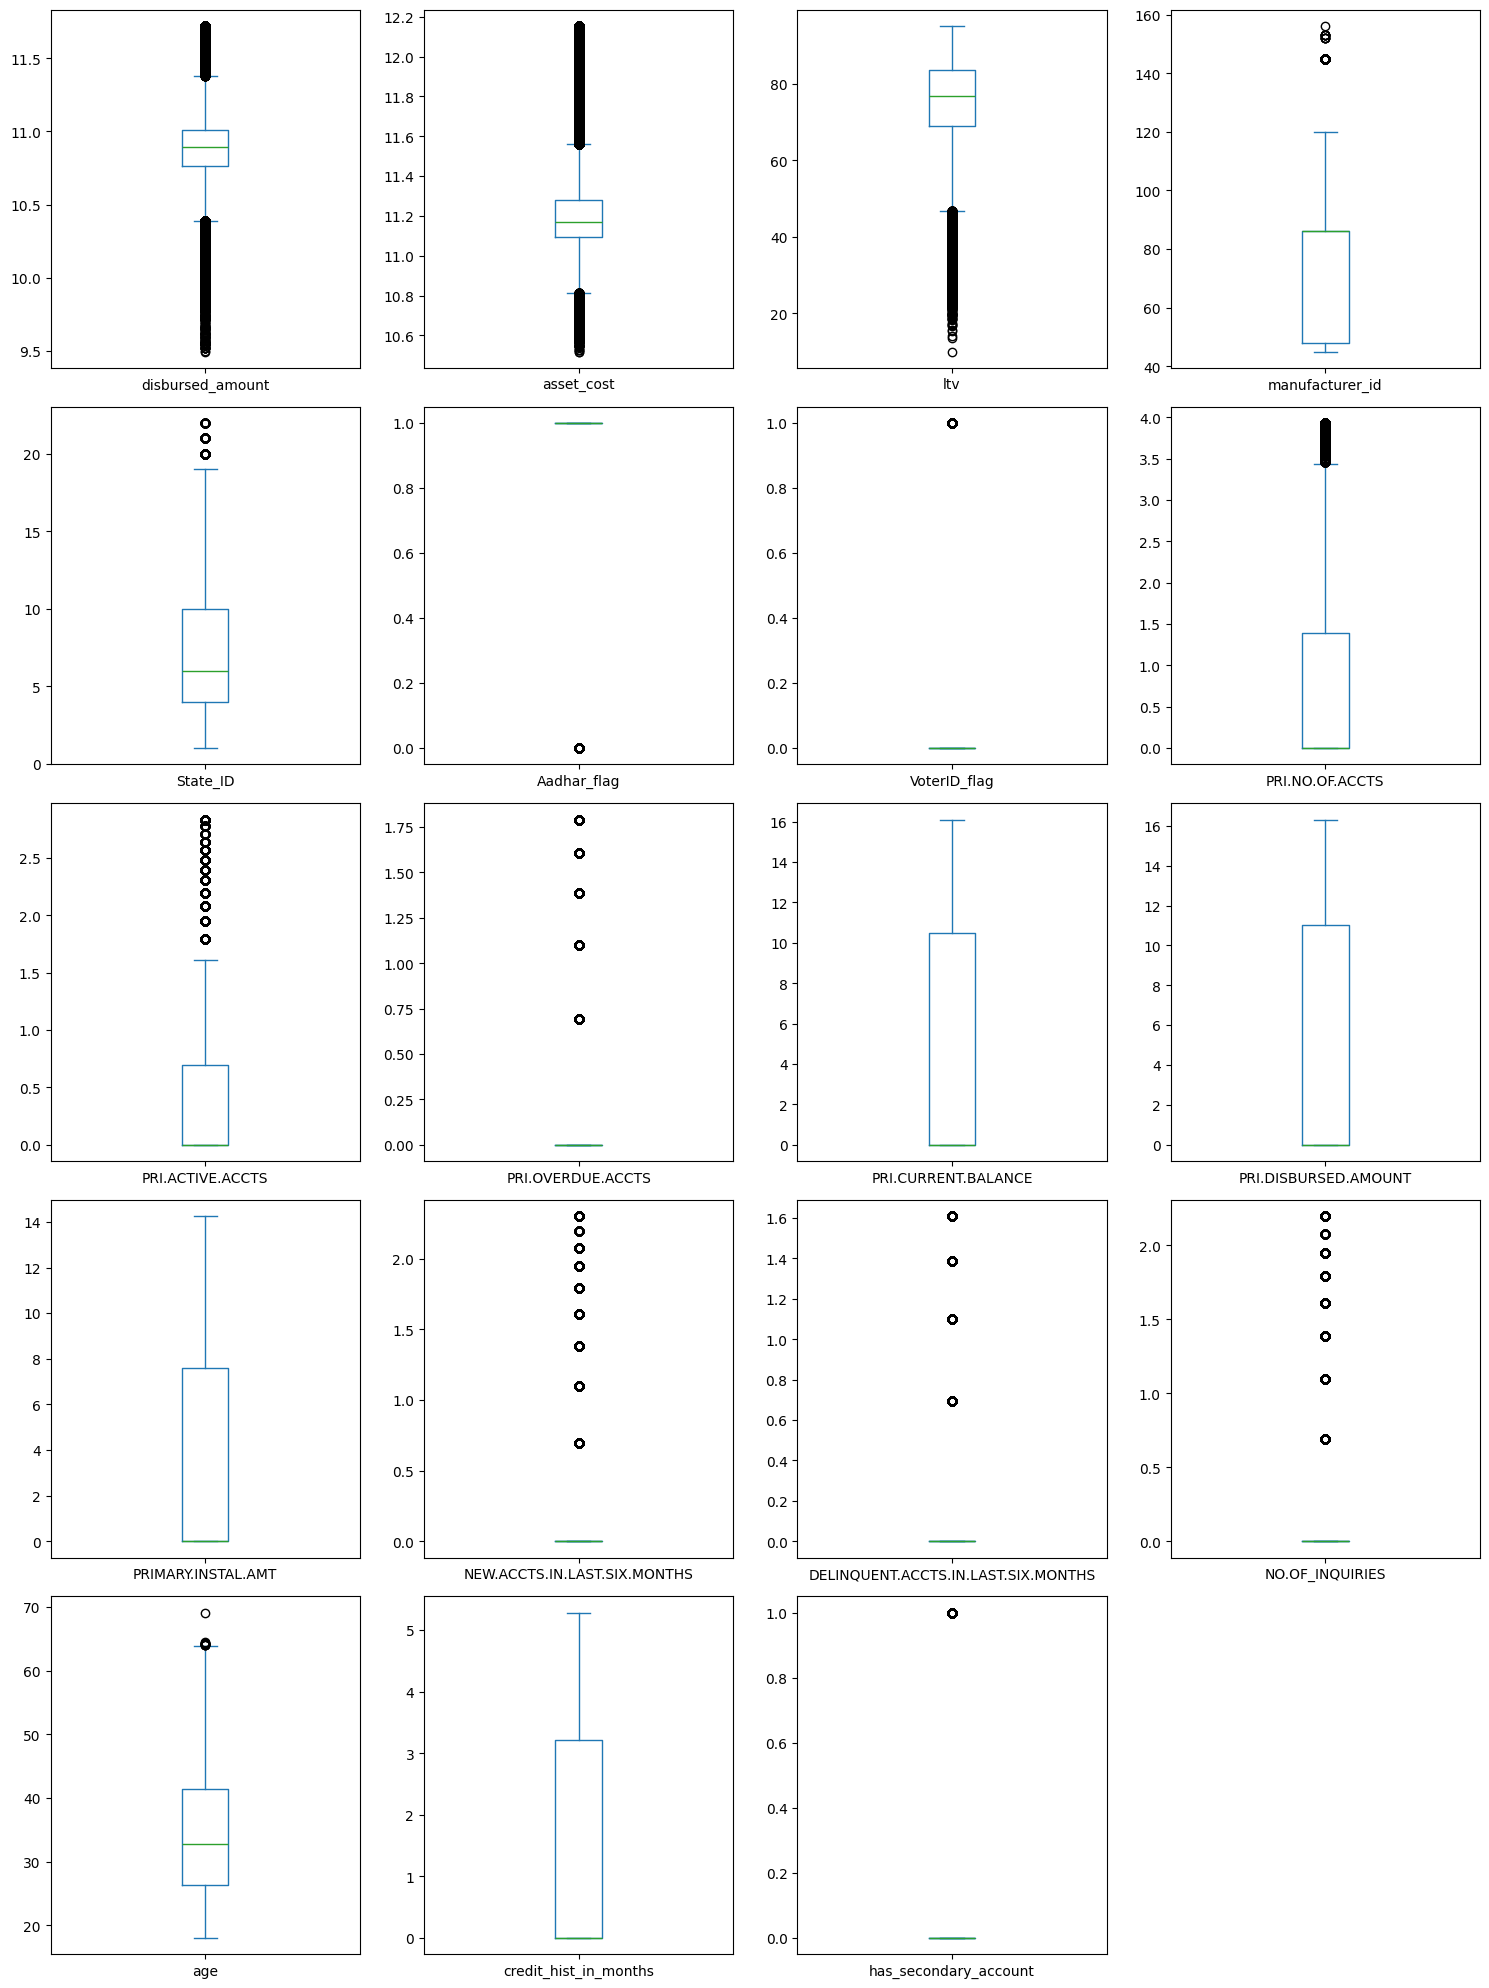

In [92]:
x_train_log.select_dtypes(include=['int64', 'float64']).plot(kind='box',subplots=True,layout=(-1,4),figsize=(15,20))
plt.tight_layout()
plt.show()

In [93]:
x_train_log.head()

,disbursed_amount,asset_cost,ltv,manufacturer_id,Employment.Type,State_ID,Aadhar_flag,VoterID_flag,PERFORM_CNS.SCORE.DESCRIPTION,PRI.NO.OF.ACCTS,...,PRI.OVERDUE.ACCTS,PRI.CURRENT.BALANCE,PRI.DISBURSED.AMOUNT,PRIMARY.INSTAL.AMT,NEW.ACCTS.IN.LAST.SIX.MONTHS,DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS,NO.OF_INQUIRIES,age,credit_hist_in_months,has_secondary_account
192380,10.953610,11.123299,88.59,86,Salaried,9,1,0,F-Low Risk,1.791759,...,0.000000,11.064856,11.529586,8.108021,1.386294,0.0,0.000000,35.624914,2.484907,0
43291,10.750342,11.247748,65.18,45,Self employed,3,1,0,No Bureau History Available,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,36.657084,0.000000,0
210644,10.324990,11.220472,41.53,86,Self employed,17,1,0,No Bureau History Available,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,34.724162,0.000000,0
50259,11.042089,11.430967,70.01,48,Self employed,3,1,0,C-Very Low Risk,1.386294,...,0.000000,10.606709,11.020284,8.815370,0.693147,0.0,0.000000,25.420945,3.135494,0
158140,10.906250,11.074436,87.60,45,Self employed,4,1,0,M-Very High Risk,0.693147,...,0.693147,0.000000,0.000000,0.000000,0.000000,0.0,1.098612,48.134155,0.000000,0


In [96]:
x_train_log.to_csv("x_train_log.csv")

In [94]:
x_train_log.dtypes


disbursed_amount                       float64
asset_cost                             float64
ltv                                    float64
manufacturer_id                          int64
Employment.Type                         object
State_ID                                 int64
Aadhar_flag                              int64
VoterID_flag                             int64
PERFORM_CNS.SCORE.DESCRIPTION           object
PRI.NO.OF.ACCTS                        float64
PRI.ACTIVE.ACCTS                       float64
PRI.OVERDUE.ACCTS                      float64
PRI.CURRENT.BALANCE                    float64
PRI.DISBURSED.AMOUNT                   float64
PRIMARY.INSTAL.AMT                     float64
NEW.ACCTS.IN.LAST.SIX.MONTHS           float64
DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS    float64
NO.OF_INQUIRIES                        float64
age                                    float64
credit_hist_in_months                  float64
has_secondary_account                    int64
dtype: object

In [97]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

cat_cols = ["Employment.Type", "PERFORM_CNS.SCORE.DESCRIPTION", "manufacturer_id", "State_ID"]
num_cols = [c for c in x_train_log.columns if c not in cat_cols]

print(x_train_log[num_cols].dtypes.unique())   # should show only int64 and float64

prep_log = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

# quick test: learn from train, apply to both
Xtr_log = prep_log.fit_transform(x_train_log)
Xte_log = prep_log.transform(x_test_log)
print(Xtr_log.shape, Xte_log.shape)

[dtype('float64') dtype('int64')]
(186522, 72) (46631, 72)


In [102]:
print(type(Xtr_log))
print(type(x_train_log))

<class 'scipy.sparse._csr.csr_matrix'>
<class 'pandas.core.frame.DataFrame'>


In [108]:
print(x_train_log.columns)

Index(['disbursed_amount', 'asset_cost', 'ltv', 'manufacturer_id',
       'Employment.Type', 'State_ID', 'Aadhar_flag', 'VoterID_flag',
       'PERFORM_CNS.SCORE.DESCRIPTION', 'PRI.NO.OF.ACCTS', 'PRI.ACTIVE.ACCTS',
       'PRI.OVERDUE.ACCTS', 'PRI.CURRENT.BALANCE', 'PRI.DISBURSED.AMOUNT',
       'PRIMARY.INSTAL.AMT', 'NEW.ACCTS.IN.LAST.SIX.MONTHS',
       'DELINQUENT.ACCTS.IN.LAST.SIX.MONTHS', 'NO.OF_INQUIRIES', 'age',
       'credit_hist_in_months', 'has_secondary_account'],
      dtype='object')


In [109]:
Xtr_df = pd.DataFrame(Xtr_log.toarray(),  index=x_train_log.index)
print(Xtr_df.columns)
print(Xtr_df.dtypes.value_counts())   # should be all float64

RangeIndex(start=0, stop=72, step=1)
float64    72
Name: count, dtype: int64


In [111]:
x_train.dtypes

UniqueID                                 int64
disbursed_amount                         int64
asset_cost                               int64
ltv                                    float64
branch_id                                int64
supplier_id                              int64
manufacturer_id                          int64
Current_pincode_ID                       int64
Employment.Type                         object
State_ID                                 int64
Employee_code_ID                         int64
MobileNo_Avl_Flag                        int64
Aadhar_flag                              int64
PAN_flag                                 int64
VoterID_flag                             int64
Driving_flag                             int64
Passport_flag                            int64
PERFORM_CNS.SCORE                        int64
PERFORM_CNS.SCORE.DESCRIPTION           object
PRI.NO.OF.ACCTS                          int64
PRI.ACTIVE.ACCTS                         int64
PRI.OVERDUE.A

In [113]:
x_train_other=x_train.copy()
x_test_other=x_test.copy()

In [114]:
x_train_other=x_train_other.drop(columns=['PRI.SANCTIONED.AMOUNT','SEC.SANCTIONED.AMOUNT','avg_acct_age_in_months'])
x_test_other=x_test_other.drop(columns=['PRI.SANCTIONED.AMOUNT','SEC.SANCTIONED.AMOUNT','avg_acct_age_in_months'])

In [115]:
sec_cols = ["SEC.NO.OF.ACCTS", "SEC.ACTIVE.ACCTS", "SEC.OVERDUE.ACCTS", "SEC.CURRENT.BALANCE", "SEC.DISBURSED.AMOUNT", "SEC.INSTAL.AMT"]

x_train_other["has_secondary_account"] = (x_train_other["SEC.NO.OF.ACCTS"] > 0).astype(int)
x_test_other["has_secondary_account"] = (x_test_other["SEC.NO.OF.ACCTS"] > 0).astype(int)

x_train_other = x_train_other.drop(columns=sec_cols)
x_test_other = x_test_other.drop(columns=sec_cols)

In [116]:
x_train_other=x_train_other.drop(columns=['PAN_flag','MobileNo_Avl_Flag','Passport_flag','Driving_flag'])
x_test_other=x_test_other.drop(columns=['PAN_flag','MobileNo_Avl_Flag','Passport_flag','Driving_flag'])

In [117]:
x_train_other=x_train_other.drop(columns=['UniqueID','branch_id','supplier_id','Employee_code_ID','Current_pincode_ID'])
x_test_other=x_test_other.drop(columns=['UniqueID','branch_id','supplier_id','Employee_code_ID','Current_pincode_ID'])

In [118]:
x_train_other['PERFORM_CNS.SCORE.DESCRIPTION'] = x_train_other['PERFORM_CNS.SCORE.DESCRIPTION'].replace('Not Scored: More than 50 active Accounts found', 'Not Scored: Not Enough Info available on the customer')
x_test_other['PERFORM_CNS.SCORE.DESCRIPTION'] = x_test_other['PERFORM_CNS.SCORE.DESCRIPTION'].replace('Not Scored: More than 50 active Accounts found', 'Not Scored: Not Enough Info available on the customer')

In [119]:
x_train_other=x_train_other.drop(columns=['PERFORM_CNS.SCORE'])
x_test_other=x_test_other.drop(columns=['PERFORM_CNS.SCORE'])

In [120]:
x_train.dtypes

UniqueID                                 int64
disbursed_amount                         int64
asset_cost                               int64
ltv                                    float64
branch_id                                int64
supplier_id                              int64
manufacturer_id                          int64
Current_pincode_ID                       int64
Employment.Type                         object
State_ID                                 int64
Employee_code_ID                         int64
MobileNo_Avl_Flag                        int64
Aadhar_flag                              int64
PAN_flag                                 int64
VoterID_flag                             int64
Driving_flag                             int64
Passport_flag                            int64
PERFORM_CNS.SCORE                        int64
PERFORM_CNS.SCORE.DESCRIPTION           object
PRI.NO.OF.ACCTS                          int64
PRI.ACTIVE.ACCTS                         int64
PRI.OVERDUE.A

In [122]:
print(x_train_log.shape)
print(x_train_other.shape)

(186522, 21)
(186522, 21)


In [123]:
prep_other = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
], remainder="passthrough")
Xtr_other = prep_log.fit_transform(x_train_other)
Xte_other = prep_log.transform(x_test_other)
print(Xtr_other.shape, Xte_other.shape)

(186522, 72) (46631, 72)
